# We load data from the Eurocrops dataset. First, I will chooose one region and year. 

In [1]:
#set working directory to project root
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)

/Users/henristaehelin/Desktop/UZH/SDS320/project


In [2]:
from pathlib import Path

project_dir = Path("..").resolve()

images_dir = project_dir / "data/raw/imagery/sentinel2"
masks_dir = project_dir / "data/raw/raster"

print("Project:", project_dir)
print("Images exist:", images_dir.exists())
print("Masks exist:", masks_dir.exists())

Project: /Users/henristaehelin/Desktop/UZH/SDS320/project
Images exist: True
Masks exist: True


### 1. Data load. I chose to load data from germany in 2023. 

In [3]:
import geopandas as gpd
germany_2023 = gpd.read_parquet("../data/raw/vectors/dea_2023.parquet")
germany_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491..."
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615..."
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426..."
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293..."
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427..."


We have the cropfield number, the geometry, but what about the crop type label?

Could that be original_code?

In [4]:
import pandas as pd
crop_names = pd.read_csv("../data/raw/Eurocrops.csv")
crop_names.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,at,10001,NICHT DEFINIERT,not defined,3390000000,not_known_and_other,0,No specified use
1,at,105,KÖRNERMAIS,GRAIN CORN,3310106000,maize_corn_popcorn,6,Harvested as Grains
2,at,106,MAIS CORN-COB-MIX (CCM),CORN CORN-COB-MIX (CCM),3310106000,maize_corn_popcorn,0,No specified use
3,at,107,ZUCKERMAIS,SUGAR CORN,3310106000,maize_corn_popcorn,0,No specified use
4,at,109,SILOMAIS,SILO CORN,3310106000,maize_corn_popcorn,3,Fodder/Forage


This file has all the codes for each country. "nuts" is the country tag. So for italy it would be iti1. We want the table of country specific crop codes of only italy. 

In [5]:
germany_cropnames = crop_names[crop_names["nuts"] == "dea"] #select only rows with german codes
germany_cropnames.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
1809,dea,10222,Dicke Bohne,Broad bean,3310201010,beans,0,No specified use
1810,dea,112,Winterdurum (Hartweizen),Winter hard wheat / durum,3310102001,winter_durum_hard_wheat,0,No specified use
1811,dea,113,Sommerdurum (Hartweizen),Summer durum wheat / durum,3310102002,spring_durum_hard_wheat,0,No specified use
1812,dea,114,Winter-Dinkel,Winter spelt,3310110001,winter_spelt,0,No specified use
1813,dea,115,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use


Merge them with the german crop dataset, now we will have the polygons with the labels. 
#### **Consider generalizing this process into a python script that we can call upon, this would allow us to efficiently combine multiple vector datasets from different countries into one.**

In [6]:
germany_2023 = germany_2023.merge(
    germany_cropnames,
    on=["original_code"],
    how="left")
germany_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491...",dea,Blühfläche (AUM-Altmaßnahme,Flowering area (AUM-old measure),3310800000,flowers_ornamental_plants,0,No specified use
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615...",dea,Kond.-Brache (aktive Begrünun,Fallow land (active greening),3311100000,fallow_land_not_crop,0,No specified use
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293...",dea,Unbefestigte Mieten AL,unfixed rents AL,3390000000,not_known_and_other,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use


We now have polygons and labels. We will use hcat4_name as this is the harmonized label across multiple countries.

Lets also see how many unique crops there are. 

In [7]:
#see number of unique crops
print(germany_2023["hcat4_name"].nunique())
print(germany_2023["hcat4_code"].nunique()) #making sure number of unique names and codes line up

173
173


#### Thats a lot of crop types, I think its easier to learn less first. Lets see what types of crops there are.

In [8]:
print(germany_2023["hcat4_name"].unique())

['flowers_ornamental_plants' 'fallow_land_not_crop' 'permanent_grassland'
 'not_known_and_other' 'asparagus' 'potatoes' 'ericaceae_heather'
 'winter_common_soft_wheat' 'onions' 'winter_barley' 'spring_barley'
 'spring_oats' 'temporary_grassland' 'rhubarb' 'berries_berry_species'
 'clover' 'unmaintained' 'orchards_fruits' 'winter_durum_hard_wheat'
 'cereal' 'beans' 'winter_rapeseed_rape' 'conifers' 'winter_rye'
 'winter_triticale' 'miscanthus_silvergrass' 'sugar_beet'
 'alfalfa_lucerne' 'maize_corn_popcorn' 'fresh_vegetables' 'arable_crops'
 'brassicaceae_cruciferae' 'strawberries' 'sunflower'
 'winter_mixed_grains' 'winter_spelt'
 'aromatic_medicinal_culinary_plants_spices_herbs'
 'spring_common_soft_wheat' 'spring_triticale' 'peas' 'celery' 'spinach'
 'cucumber_pickle' 'winter_oats' 'lupins' 'pumpkin_squash_gourd'
 'carrots_daucus' 'seed_seedlings' 'nurseries_nursery'
 'permanent_crops_perennial' 'poaceae_grasses' 'radish' 'peony_peonies'
 'hazelnuts_hazel' 'elymus' 'edelweiss' 'other

#### There are a lot of crops that are not relevant or may be to difficult to identify. I made a list. 
fallow_land_not_crop, not_known_and_other, unmaintained, seed_seedlings, nurseries_nursery, poaceae_grasses, other_flowers_ornamental_plants, flowers_ornamental_plants, other_aromatic_medicinal_culinary_plants_spices_herbs, afforestation_reforestation, spring_mixed_grains, other_industrial_crops, other_poaceae_grasses, other_arable_land_crops

This is 14 types that don't work, this still leaves me with 159 crop types. I think it might make most sense to pick 30 and then see from there. 

#### Instead lets choose 30 different crop types. 

In [9]:
# Check the number of polygons per crop type
crop_counts = germany_2023["hcat4_name"].value_counts()

subset = [
    "winter_common_soft_wheat", "winter_barley", "spring_barley", "winter_rapeseed_rape",
    "maize_corn_popcorn", "sugar_beet", "potatoes", "winter_rye", "winter_triticale",
    "winter_oats", "spring_oats", "winter_spelt", "winter_durum_hard_wheat", "spring_common_soft_wheat",
    "winter_mixed_grains", "sunflower", "soy_soybeans", "peas", "beans", "lupins",
    "temporary_grassland", "permanent_grassland", "alfalfa_lucerne", "clover",
    "winter_emmer", "buckwheat", "miscanthus_silvergrass", "asparagus", "strawberries", "carrots_daucus",
]

print(crop_counts.reindex(subset, fill_value=0))

hcat4_name
winter_common_soft_wheat     69959
winter_barley                43410
spring_barley                 3529
winter_rapeseed_rape         16689
maize_corn_popcorn           91195
sugar_beet                   13079
potatoes                     11308
winter_rye                   15277
winter_triticale             17376
winter_oats                    536
spring_oats                   3289
winter_spelt                   808
winter_durum_hard_wheat        685
spring_common_soft_wheat      1320
winter_mixed_grains             85
sunflower                      409
soy_soybeans                   220
peas                          2117
beans                         3072
lupins                         250
temporary_grassland          28327
permanent_grassland         294894
alfalfa_lucerne               1506
clover                        5298
winter_emmer                    28
buckwheat                       34
miscanthus_silvergrass         790
asparagus                     1672
strawberr

#### Lets create a subset from these crop types, from this we will choose scenes that have at least 10 different crop types.

In [10]:
# Keep only the 30 selected crop types
reduced_crops = germany_2023[
    germany_2023["hcat4_name"].isin(subset)
].copy()

print("Original polygons:", len(germany_2023))
print("Subset polygons:", len(reduced_crops))
print("Crop types present:", reduced_crops["hcat4_name"].nunique())

reduced_crops.head(5)

Original polygons: 748208
Subset polygons: 629482
Crop types present: 30


,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use
6,714367,602,7209215,0.6296,0.629910,"MULTIPOLYGON (((4115046.183 3117774.226, 41151...",dea,Kartoffeln,potatoes,3310300000,potatoes,0,No specified use
9,716260,115,7061460,2.4301,2.432082,"MULTIPOLYGON (((4243063.131 3249725.238, 42432...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use
11,716867,115,7132898,2.0211,2.022715,"MULTIPOLYGON (((4242002.866 3240369.434, 42420...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use


In [11]:
# Define consistent crop IDs before selecting areas
crop_mapping = {
    name: i + 1
    for i, name in enumerate(
        sorted(reduced_crops["hcat4_name"].dropna().unique())
    )
}

assert len(crop_mapping) == 30
print(crop_mapping)

{'alfalfa_lucerne': 1, 'asparagus': 2, 'beans': 3, 'buckwheat': 4, 'carrots_daucus': 5, 'clover': 6, 'lupins': 7, 'maize_corn_popcorn': 8, 'miscanthus_silvergrass': 9, 'peas': 10, 'permanent_grassland': 11, 'potatoes': 12, 'soy_soybeans': 13, 'spring_barley': 14, 'spring_common_soft_wheat': 15, 'spring_oats': 16, 'strawberries': 17, 'sugar_beet': 18, 'sunflower': 19, 'temporary_grassland': 20, 'winter_barley': 21, 'winter_common_soft_wheat': 22, 'winter_durum_hard_wheat': 23, 'winter_emmer': 24, 'winter_mixed_grains': 25, 'winter_oats': 26, 'winter_rapeseed_rape': 27, 'winter_rye': 28, 'winter_spelt': 29, 'winter_triticale': 30}


#### Now we want to select areas that have at least 10 different crop types. 

In [12]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box

# Use the filtered crop dataset
germany_utm = reduced_crops.to_crs("EPSG:32632")

minx, miny, maxx, maxy = germany_utm.total_bounds #sets the bounds the polygons based on germany
cell_size = 2000  # 2 km, considering 10m is pixel this makes an area of 200 by 200 pixels

x_coords = np.arange(
    np.floor(minx / cell_size) * cell_size,
    maxx,
    cell_size
)
y_coords = np.arange(
    np.floor(miny / cell_size) * cell_size,
    maxy,
    cell_size
)

grid = gpd.GeoDataFrame(
    {"area_id": range(len(x_coords) * len(y_coords))},
    geometry=[
        box(x, y, x + cell_size, y + cell_size)
        for x in x_coords
        for y in y_coords
    ],
    crs=germany_utm.crs
)

# Count crop types intersecting each grid cell
joined = gpd.sjoin(
    germany_utm[["hcat4_name", "geometry"]],
    grid[["area_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

crop_counts = (
    joined.groupby("area_id")["hcat4_name"]
    .nunique()
    .rename("n_crop_types")
)

grid = grid.join(crop_counts, on="area_id")
grid["n_crop_types"] = grid["n_crop_types"].fillna(0).astype(int)

# Find areas with at least 10 different crop types
candidates = (
    grid[grid["n_crop_types"] >= 10]
    .sort_values("n_crop_types", ascending=False)
    .copy()
)

print("Suitable areas found:", len(candidates))
display(candidates[["area_id", "n_crop_types"]].head(20))

Suitable areas found: 3327


,area_id,n_crop_types
4699,4699,19
5192,5192,19
3712,3712,19
10643,10643,19
3730,3730,18
12763,12763,18
14336,14336,18
2848,2848,18
3369,3369,18
2366,2366,18


We have lots of suitable areas, lets select the 5 with the most crop types. 

In [13]:
selected = []

for _, candidate in candidates.iterrows():
    if all(
        not candidate.geometry.intersects(existing.geometry)
        for existing in selected
    ):
        selected.append(candidate)

    if len(selected) == 5:
        break

selected_areas = gpd.GeoDataFrame(
    selected,
    crs=grid.crs
)

print(f"Selected {len(selected_areas)} areas")
display(selected_areas[["area_id", "n_crop_types"]])

Selected 5 areas


,area_id,n_crop_types
4699,4699,19
5192,5192,19
3712,3712,19
10643,10643,19
3730,3730,18


#### We now have 5 suitable 2 by 2 km areas that we can use. We can combine them with sentinel 2 data.

### 1a. Select additional, larger training areas

In [14]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box

# 512 Sentinel-2 pixels × 10 meters
new_cell_size = 5120

germany_utm = reduced_crops.to_crs("EPSG:32632")

# Preserve the five original selected areas
existing_areas = selected_areas.to_crs(germany_utm.crs).copy()

minx, miny, maxx, maxy = germany_utm.total_bounds

x_coords = np.arange(
    np.floor(minx / new_cell_size) * new_cell_size,
    maxx,
    new_cell_size
)

y_coords = np.arange(
    np.floor(miny / new_cell_size) * new_cell_size,
    maxy,
    new_cell_size
)

large_grid = gpd.GeoDataFrame(
    geometry=[
        box(x, y, x + new_cell_size, y + new_cell_size)
        for x in x_coords
        for y in y_coords
    ],
    crs=germany_utm.crs,
)

large_grid["grid_id"] = np.arange(len(large_grid))

# Use field centroids to screen for crop diversity
field_points = germany_utm[["hcat4_name", "geometry"]].copy()
field_points["geometry"] = field_points.geometry.centroid

joined = gpd.sjoin(
    field_points,
    large_grid[["grid_id", "geometry"]],
    how="inner",
    predicate="within",
)

crop_types_by_area = (
    joined.groupby("grid_id")["hcat4_name"]
    .agg(lambda values: set(values.dropna()))
)

large_grid["crop_types"] = large_grid["grid_id"].map(
    crop_types_by_area
)

large_grid["crop_types"] = large_grid["crop_types"].apply(
    lambda x: x if isinstance(x, set) else set()
)

large_grid["n_crop_types"] = large_grid["crop_types"].apply(len)

# At least 10 crop types
large_candidates = large_grid[
    large_grid["n_crop_types"] >= 10
].copy()

# Exclude the existing train, validation, and test areas,
# with a 1 km separation buffer.
protected_geometry = existing_areas.geometry.buffer(1000).union_all()

large_candidates = large_candidates[
    ~large_candidates.geometry.intersects(protected_geometry)
].copy()

print("Suitable new areas:", len(large_candidates))
display(
    large_candidates[
        ["grid_id", "n_crop_types"]
    ].sort_values("n_crop_types", ascending=False).head(20)
)

Suitable new areas: 1078


,grid_id,n_crop_types
546,546,24
2147,2147,23
593,593,23
545,545,23
680,680,23
450,450,23
631,631,23
318,318,23
449,449,22
1712,1712,22


Now instead of selecting the 5 with the most crop types, lets select more and ensure that ones with underrepresented crop types are also included. 

In [15]:
import rasterio

train_label_dir = project_dir / "data/processed/tiles/train/labels"

train_counts = np.zeros(30, dtype=np.int64)

for path in train_label_dir.glob("*.tif"):
    with rasterio.open(path) as src:
        labels = src.read(1)

    valid = (labels >= 1) & (labels <= 30)

    train_counts += np.bincount(
        labels[valid].astype(int) - 1,
        minlength=30
    )

# Rarer crops get higher selection priority.
# Missing crops receive particularly high priority.
crop_priority = {
    name: 1 / np.sqrt(train_counts[class_id - 1] + 1)
    for name, class_id in crop_mapping.items()
}

# Normalize weights
maximum = max(crop_priority.values())
crop_priority = {
    name: weight / maximum
    for name, weight in crop_priority.items()
}

selected_new = []
covered_crops = set()

remaining = large_candidates.copy()

while len(selected_new) < 12 and not remaining.empty:

    def candidate_score(row):
        new_crops = row["crop_types"] - covered_crops

        diversity_score = sum(
            crop_priority.get(name, 0)
            for name in new_crops
        )

        return diversity_score + 0.02 * row["n_crop_types"]

    remaining["score"] = remaining.apply(candidate_score, axis=1)
    remaining = remaining.sort_values("score", ascending=False)

    # Check that selected areas contain complete crop fields,
    # not just centroids of fields crossing their boundaries.
    chosen = None

    for index, candidate in remaining.iterrows():
        crops_inside = germany_utm[
            germany_utm.geometry.within(candidate.geometry)
        ]

        if crops_inside["hcat4_name"].nunique() >= 10:
            chosen = candidate
            break

    if chosen is None:
        break

    selected_new.append(chosen)
    covered_crops.update(chosen["crop_types"])

    # Avoid neighboring or overlapping selected areas
    exclusion = chosen.geometry.buffer(1000)

    remaining = remaining[
        ~remaining.geometry.intersects(exclusion)
    ].copy()

new_training_areas = gpd.GeoDataFrame(
    selected_new,
    crs=large_candidates.crs
).reset_index(drop=True)

# Use new IDs to avoid conflicts with your old area IDs.
new_training_areas["area_id"] = (
    np.arange(len(new_training_areas)) + 20001
)

print("Selected new training areas:", len(new_training_areas))

display(
    new_training_areas[
        ["area_id", "n_crop_types", "score"]
    ]
)

Selected new training areas: 12


,area_id,n_crop_types,score
0,20001,19,3.750690
1,20002,22,1.864414
2,20003,23,0.752618
3,20004,23,0.460000
4,20005,23,0.460000
5,20006,23,0.460000
6,20007,23,0.460000
7,20008,22,0.440000
8,20009,22,0.440000
9,20010,22,0.440000


Check how many crop types are actually represented. 

In [16]:
# Check crop diversity using fully contained fields
all_new_crops = set()
results = []

for _, area in new_training_areas.iterrows():

    complete = germany_utm[
        germany_utm.geometry.within(area.geometry)
    ]

    crop_types = set(complete["hcat4_name"].dropna())
    all_new_crops.update(crop_types)

    results.append({
        "area_id": area["area_id"],
        "complete_fields": len(complete),
        "complete_field_crop_types": len(crop_types),
    })

display(pd.DataFrame(results))

# Compare with your 30 selected crop classes
target_crops = set(crop_mapping.keys())

covered = target_crops & all_new_crops
missing = target_crops - all_new_crops

print(f"\nTarget crops represented: {len(covered)} / 30")
print("Missing crop types:", sorted(missing))

,area_id,complete_fields,complete_field_crop_types
0,20001,281,19
1,20002,658,22
2,20003,534,23
3,20004,597,23
4,20005,627,22
5,20006,489,23
6,20007,334,23
7,20008,666,22
8,20009,879,22
9,20010,1096,22



Target crops represented: 30 / 30
Missing crop types: []


#### Now all 30 crop types are actually represented in our training data as compared to before with only our 5 areas that had a lot of crop types missing. 
Lets also quickly visualize the selecte areas on map. 

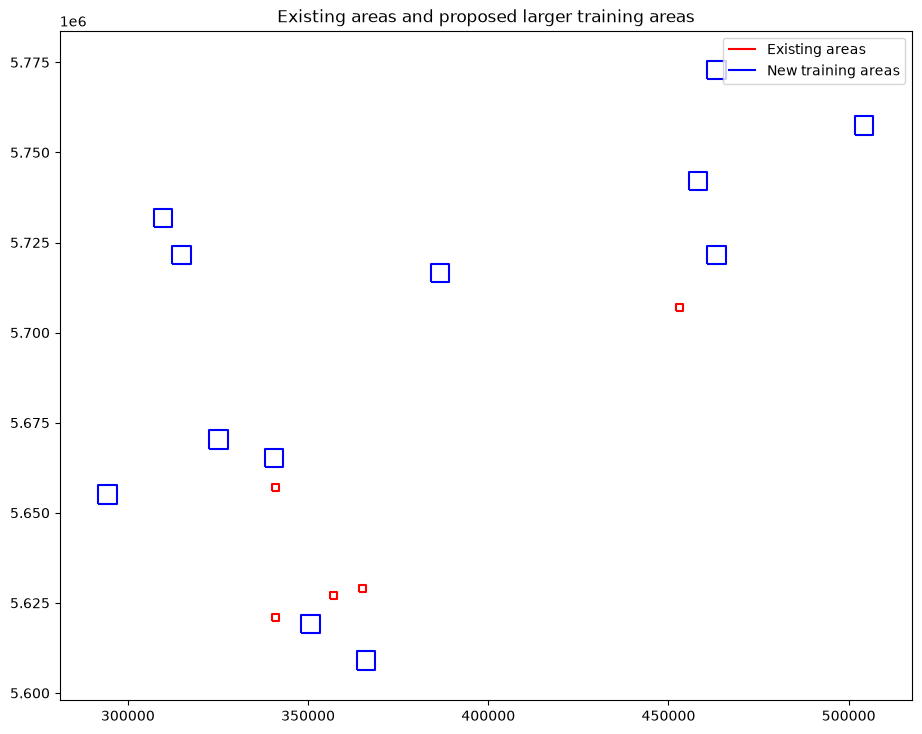

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 9))

existing_areas.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5,
    label="Existing areas",
)

new_training_areas.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=1.5,
    label="New training areas",
)

ax.set_title("Existing areas and proposed larger training areas")
ax.set_aspect("equal")
ax.legend()
plt.show()

They are separate enough from each other and the existing areas.

### 2. We want to combine it now with the Sentinel-2 raster data and load them together. 

We will add the new areas now, they will all be training data, we define the split later but can do it now as well. 

In [18]:
# Existing areas
existing_split = {
    4699: "train",
    5192: "train",
    3712: "train",
    10643: "val",
    3730: "test",
}

# Add all 12 new areas to training only
new_area_ids = new_training_areas["area_id"].astype(int).tolist()

split_by_area = {
    **existing_split,
    **{area_id: "train" for area_id in new_area_ids},
}

area_ids = list(split_by_area)

print("Total areas:", len(area_ids))
print("Training areas:", sum(s == "train" for s in split_by_area.values()))
print("Validation areas:", sum(s == "val" for s in split_by_area.values()))
print("Test areas:", sum(s == "test" for s in split_by_area.values()))

Total areas: 17
Training areas: 15
Validation areas: 1
Test areas: 1


In [19]:
reduced_crops.crs
#first check CRS

<Projected CRS: EPSG:3035>
Name: ETRS89-extended / LAEA Europe
Axis Info [cartesian]:
- Y[north]: Northing (metre)
- X[east]: Easting (metre)
Area of Use:
- name: Europe - European Union (EU) countries and candidates. Europe - onshore and offshore: Albania; Andorra; Austria; Belgium; Bosnia and Herzegovina; Bulgaria; Croatia; Cyprus; Czechia; Denmark; Estonia; Faroe Islands; Finland; France; Germany; Gibraltar; Greece; Hungary; Iceland; Ireland; Italy; Kosovo; Latvia; Liechtenstein; Lithuania; Luxembourg; Malta; Monaco; Montenegro; Netherlands; North Macedonia; Norway including Svalbard and Jan Mayen; Poland; Portugal including Madeira and Azores; Romania; San Marino; Serbia; Slovakia; Slovenia; Spain including Canary Islands; Sweden; Switzerland; Türkiye (Turkey); United Kingdom (UK) including Channel Islands and Isle of Man; Vatican City State.
- bounds: (-35.58, 24.6, 44.83, 84.73)
Coordinate Operation:
- name: Europe Equal Area 2001
- method: Lambert Azimuthal Equal Area
Datum: Eur

In [20]:
import pandas as pd
import geopandas as gpd

# Original five areas + 12 new training areas
all_areas = gpd.GeoDataFrame(
    pd.concat([
        selected_areas[["area_id", "geometry"]].to_crs("EPSG:4326"),
        new_training_areas[["area_id", "geometry"]].to_crs("EPSG:4326"),
    ], ignore_index=True),
    crs="EPSG:4326",
)

all_areas["area_id"] = all_areas["area_id"].astype(int)

assert all_areas["area_id"].is_unique

selected_wgs84 = all_areas

print("Total areas:", len(selected_wgs84))
print("CRS:", selected_wgs84.crs)

Total areas: 17
CRS: EPSG:4326


In [21]:
from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

items_by_area = {}

for _, area in selected_wgs84.iterrows():
    area_id = int(area["area_id"])

    output_path = (
        project_dir / "data/raw/imagery/sentinel2_10band" / f"germany_2023_area_{area_id}.tif"
    )

    if output_path.exists():
        print(f"Area {area_id}: imagery already exists — skipping search")
        continue

    search = pc_catalog.search(
        collections=["sentinel-2-l2a"],
        intersects=area.geometry.__geo_interface__,
        datetime="2023-01-01/2023-12-31",
        query={"eo:cloud_cover": {"lt": 20}},
        max_items=10,
    )

    items = list(search.items())
    items_by_area[area_id] = items

    print(f"Area {area_id}: found {len(items)} scenes")

Area 4699: found 10 scenes
Area 5192: imagery already exists — skipping search
Area 3712: imagery already exists — skipping search
Area 10643: imagery already exists — skipping search
Area 3730: imagery already exists — skipping search
Area 20001: imagery already exists — skipping search
Area 20002: imagery already exists — skipping search
Area 20003: imagery already exists — skipping search
Area 20004: imagery already exists — skipping search
Area 20005: imagery already exists — skipping search
Area 20006: imagery already exists — skipping search
Area 20007: imagery already exists — skipping search
Area 20008: imagery already exists — skipping search
Area 20009: imagery already exists — skipping search
Area 20010: imagery already exists — skipping search
Area 20011: imagery already exists — skipping search
Area 20012: imagery already exists — skipping search


##### Select the best scenes (least cloud cover) for each area. 

In [22]:
import planetary_computer as pc

best_items = {}

for area_id, items in items_by_area.items():

    if not items:
        print(f"No Sentinel-2 scenes found for area {area_id}")
        continue

    items_sorted = sorted(
        items,
        key=lambda item: item.properties.get("eo:cloud_cover", 999),
    )
# looks through the scenes and chooses the one with the least cloud cover calls it s2_item
    s2_item = items_sorted[0]
    best_items[area_id] = s2_item
# this is then added to the dictionary of best_items
    print(f"\nArea: {area_id}")
    print("Selected item:", s2_item.id)
    print("Date:", s2_item.datetime)
    print(
        "Cloud cover:",
        round(s2_item.properties.get("eo:cloud_cover", 999), 2),
    )

    print("Useful assets:")
    for key in ["B02", "B03", "B04", "B08", "SCL", "visual"]:
        if key in s2_item.assets:
            print(key, "-", s2_item.assets[key].title)


Area: 4699
Selected item: S2B_MSIL2A_20230911T102609_R108_T32ULB_20230911T183201
Date: 2023-09-11 10:26:09.024000+00:00
Cloud cover: 0.0
Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image


##### Save the bands for each scene in each area.

In [23]:
from pathlib import Path
from scripts.Raster_helper_functions import save_multiband_subset
import rasterio

output_dir = images_dir
output_dir.mkdir(parents=True, exist_ok=True)

s2_paths = {}

for _, area in selected_wgs84.iterrows():
    area_id = int(area["area_id"])

    output_path = (
        output_dir / f"germany_2023_area_{area_id}.tif"
    )

    # Reuse imagery already downloaded
    if output_path.exists():
        s2_paths[area_id] = output_path
        print(f"Area {area_id}: using existing imagery")
        continue

    if area_id not in best_items:
        print(f"Area {area_id}: no suitable scene found — skipping")
        continue

    s2_item = best_items[area_id]
    bbox_wgs84 = list(area.geometry.bounds)

    # Download Sentinel-2 imagery
    s2_path = save_multiband_subset(
        item=s2_item,
        asset_keys=[
            "B02",  # Blue
            "B03",  # Green
            "B04",  # Red
            "B08",  # Near-infrared
        ],
        bbox_wgs84=bbox_wgs84,
        output_path=output_path,
    )

    # Save acquisition metadata
    with rasterio.open(s2_path, "r+") as dst:
        dst.update_tags(
            acquisition_datetime=s2_item.datetime.isoformat(),
            stac_item_id=s2_item.id,
            cloud_cover=str(s2_item.properties.get("eo:cloud_cover")),
        )

    s2_paths[area_id] = Path(s2_path)

    print(f"Area {area_id}: downloaded")

print(f"\nAvailable imagery: {len(s2_paths)} / {len(selected_wgs84)}")

Area 4699: using existing imagery
Area 5192: using existing imagery
Area 3712: using existing imagery
Area 10643: using existing imagery
Area 3730: using existing imagery
Area 20001: using existing imagery
Area 20002: using existing imagery
Area 20003: using existing imagery
Area 20004: using existing imagery
Area 20005: using existing imagery
Area 20006: using existing imagery
Area 20007: using existing imagery
Area 20008: using existing imagery
Area 20009: using existing imagery
Area 20010: using existing imagery
Area 20011: using existing imagery
Area 20012: using existing imagery

Available imagery: 17 / 17


### Ten-band Sentinel-2 experiment (separate dataset)
Use the existing 4-band grids, save red-edge/SWIR bands at aligned 10 m pixel spacing. Re-run scene search (cell 41) and selection (43) first. This is a new dataset; source rasters are not modified.

In [24]:
# Download 10-band Sentinel-2 scenes on the grids of the existing 4-band rasters.
# Keep all original 4-band images and masks intact.
from pathlib import Path
import numpy as np
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
import planetary_computer as pc

bands_10 = ["B02", "B03", "B04", "B08", "B05", "B06", "B07", "B8A", "B11", "B12"]
output_dir_10 = project_dir / "data/raw/imagery/sentinel2_10band"
output_dir_10.mkdir(parents=True, exist_ok=True)
s2_paths_10 = {}

for _, area in selected_wgs84.iterrows():
    area_id = int(area["area_id"])
    original_path = images_dir / f"germany_2023_area_{area_id}.tif"
    output_path = output_dir_10 / f"germany_2023_area_{area_id}.tif"
    temporary_path = output_path.with_suffix(".partial.tif")

    if output_path.exists():
        with rasterio.open(output_path) as existing:
            if existing.count != 10 or not existing.tags().get("stac_item_id"):
                raise ValueError(f"Incomplete or untagged 10-band image: {output_path}. Inspect/remove that file before rerunning.")
        s2_paths_10[area_id] = output_path
        print(f"Area {area_id}: existing 10-band image")
        continue

    if not original_path.exists():
        raise FileNotFoundError(f"Original reference grid missing: {original_path}")
    if area_id not in best_items:
        raise ValueError(f"Area {area_id}: no STAC scene selected. Run scene-search and selection cells first.")

    # Fetch the SAME scene ID afresh and generate one signed set of URLs.
    selected_item = best_items[area_id]
    fresh_item = pc_catalog.get_collection("sentinel-2-l2a").get_item(selected_item.id)
    if fresh_item is None:
        raise ValueError(f"STAC scene missing: {selected_item.id}")
    signed_item = pc.sign(fresh_item)

    with rasterio.open(original_path) as reference:
        if reference.count != 4:
            raise ValueError(f"Expected four-band reference raster: {original_path}")
        profile = reference.profile.copy()

    profile.update(count=10, dtype="uint16", nodata=0, compress="deflate")

    try:
        with rasterio.open(temporary_path, "w", **profile) as dst:
            for band_index, band_name in enumerate(bands_10, start=1):
                asset = signed_item.assets[band_name]
                with rasterio.open(asset.href) as source:
                    # Bilinear is used only for the bands natively sampled at 20 m.
                    method = (Resampling.bilinear if band_name in
                              {"B05", "B06", "B07", "B8A", "B11", "B12"}
                              else Resampling.nearest)
                    with WarpedVRT(
                        source,
                        crs=profile["crs"], transform=profile["transform"],
                        width=profile["width"], height=profile["height"],
                        resampling=method, nodata=0,
                    ) as vrt:
                        dst.write(vrt.read(1), band_index)
                dst.set_band_description(band_index, band_name)
            dst.update_tags(
                acquisition_datetime=fresh_item.datetime.isoformat(),
                stac_item_id=fresh_item.id,
                cloud_cover=str(fresh_item.properties.get("eo:cloud_cover")),
            )
        # Rename only on success; failed downloads cannot be mistaken for finished files.
        temporary_path.replace(output_path)
    except Exception:
        temporary_path.unlink(missing_ok=True)
        raise

    s2_paths_10[area_id] = output_path
    print(f"Area {area_id}: saved ten bands — {fresh_item.datetime.date()}")

print(f"\nTen-band images: {len(s2_paths_10)} / {len(selected_wgs84)}")


Area 4699: saved ten bands — 2023-09-11
Area 5192: existing 10-band image
Area 3712: existing 10-band image
Area 10643: existing 10-band image
Area 3730: existing 10-band image
Area 20001: existing 10-band image
Area 20002: existing 10-band image
Area 20003: existing 10-band image
Area 20004: existing 10-band image
Area 20005: existing 10-band image
Area 20006: existing 10-band image
Area 20007: existing 10-band image
Area 20008: existing 10-band image
Area 20009: existing 10-band image
Area 20010: existing 10-band image
Area 20011: existing 10-band image
Area 20012: existing 10-band image

Ten-band images: 17 / 17


In [25]:
# Verify all 10-band scenes against their original 4-band grids and cleaned masks.
import pandas as pd
import rasterio

records = []
for area_id in split_by_area:
    path = output_dir_10 / f"germany_2023_area_{area_id}.tif"
    old_path = images_dir / f"germany_2023_area_{area_id}.tif"
    mask_path = project_dir / "data/processed/masks_edge_ignored" / f"germany_mask_{area_id}.tif"
    if not path.exists():
        raise FileNotFoundError(path)
    with rasterio.open(path) as new, rasterio.open(old_path) as old, rasterio.open(mask_path) as mask:
        assert new.count == 10, (area_id, new.count)
        assert (new.crs, new.transform, new.width, new.height) == (old.crs, old.transform, old.width, old.height)
        assert (new.crs, new.transform, new.width, new.height) == (mask.crs, mask.transform, mask.width, mask.height)
        assert new.tags().get("acquisition_datetime"), area_id
        records.append({"area_id": area_id, "split": split_by_area[area_id],
                        "date": new.tags()["acquisition_datetime"],
                        "scene_id": new.tags()["stac_item_id"], "bands": new.count})
display(pd.DataFrame(records).sort_values("area_id"))
print("All ten-band images aligned with existing masks.")


,area_id,split,date,scene_id,bands
2,3712,train,2023-09-11T10:26:09.024000+00:00,S2B_MSIL2A_20230911T102609_R108_T32ULB_2023091...,10
4,3730,test,2023-08-10T10:36:31.024000+00:00,S2A_MSIL2A_20230810T103631_R008_T31UGS_2024102...,10
0,4699,train,2023-09-11T10:26:09.024000+00:00,S2B_MSIL2A_20230911T102609_R108_T32ULB_2023091...,10
1,5192,train,2023-09-11T10:26:09.024000+00:00,S2B_MSIL2A_20230911T102609_R108_T32ULB_2023091...,10
3,10643,val,2023-09-09T10:36:31.024000+00:00,S2A_MSIL2A_20230909T103631_R008_T32UMC_2024110...,10
5,20001,train,2023-09-11T10:26:09.024000+00:00,S2B_MSIL2A_20230911T102609_R108_T31UGT_2023091...,10
6,20002,train,2023-09-09T10:36:31.024000+00:00,S2A_MSIL2A_20230909T103631_R008_T32UMC_2024110...,10
7,20003,train,2023-08-10T10:36:31.024000+00:00,S2A_MSIL2A_20230810T103631_R008_T31UGS_2024102...,10
8,20004,train,2023-09-09T10:36:31.024000+00:00,S2A_MSIL2A_20230909T103631_R008_T32ULC_2024110...,10
9,20005,train,2023-08-10T10:36:31.024000+00:00,S2A_MSIL2A_20230810T103631_R008_T31UGS_2024102...,10


All ten-band images aligned with existing masks.


#### We can check the acquisition dates and metadata:

In [26]:
import rasterio
import pandas as pd

records = []

for path in sorted(images_dir.glob("*.tif")):
    with rasterio.open(path) as src:
        records.append({
            "image": path.name,
            "date": src.tags().get("acquisition_datetime", "Not stored"),
            "scene_id": src.tags().get("stac_item_id", "Not stored"),
            "cloud_cover": src.tags().get("cloud_cover", "Not stored"),
        })

dates_df = pd.DataFrame(records)
display(dates_df)

,image,date,scene_id,cloud_cover
0,germany_2023_area_10643.tif,Not stored,Not stored,Not stored
1,germany_2023_area_20001.tif,Not stored,Not stored,Not stored
2,germany_2023_area_20002.tif,Not stored,Not stored,Not stored
3,germany_2023_area_20003.tif,Not stored,Not stored,Not stored
4,germany_2023_area_20004.tif,Not stored,Not stored,Not stored
5,germany_2023_area_20005.tif,Not stored,Not stored,Not stored
6,germany_2023_area_20006.tif,Not stored,Not stored,Not stored
7,germany_2023_area_20007.tif,Not stored,Not stored,Not stored
8,germany_2023_area_20008.tif,Not stored,Not stored,Not stored
9,germany_2023_area_20009.tif,Not stored,Not stored,Not stored


Have code that saves the metadata of the scenes for us so we can access. This is includes when the scenes were taken. 

#### A check for CRS and raster dimensions. 

In [27]:
import pandas as pd
import rasterio

raster_info = []

for area_id, path in sorted(s2_paths.items()):
    with rasterio.open(path) as src:
        raster_info.append({
            "area_id": area_id,
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "CRS": str(src.crs),
            "resolution": src.res,
        })

raster_info = pd.DataFrame(raster_info)

display(raster_info)

assert (raster_info["bands"] == 4).all()

,area_id,width,height,bands,CRS,resolution
0,3712,212,200,4,EPSG:32632,"(10.0, 10.0)"
1,3730,195,216,4,EPSG:32631,"(10.0, 10.0)"
2,4699,211,200,4,EPSG:32632,"(10.0, 10.0)"
3,5192,210,200,4,EPSG:32632,"(10.0, 10.0)"
4,10643,204,200,4,EPSG:32632,"(10.0, 10.0)"
5,20001,492,554,4,EPSG:32631,"(10.0, 10.0)"
6,20002,518,512,4,EPSG:32632,"(10.0, 10.0)"
7,20003,502,554,4,EPSG:32631,"(10.0, 10.0)"
8,20004,541,511,4,EPSG:32632,"(10.0, 10.0)"
9,20005,504,554,4,EPSG:32631,"(10.0, 10.0)"


Check the that there are 4 bands for each raster image. That the resolution is correct and the crs is not None.

In [28]:
for area_id, path in sorted(s2_paths.items()):
    with rasterio.open(path) as src:
        assert src.count == 4, f"Area {area_id}: expected 4 bands"

        assert src.res == (10.0, 10.0), (
            f"Area {area_id}: unexpected resolution {src.res}"
        )

        assert src.crs is not None, (
            f"Area {area_id}: missing CRS"
        )

print("All 17 Sentinel-2 images passed the checks.")

All 17 Sentinel-2 images passed the checks.


In [29]:
import leafmap
import rasterio

maps = {}

for area_id in [20001, 20002, 20003]:
    raster_path = s2_paths[area_id]

    # Get the crop fields for this selected area

    area = all_areas.loc[
    all_areas["area_id"] == area_id
    ].to_crs(reduced_crops.crs)
    
    crop_fields = gpd.clip(
        reduced_crops,
        area
    )

    m = leafmap.Map(height="500px")
    m.add_basemap("Esri.WorldImagery")

    # True-colour RGB (B04, B03, B02)
    m.add_raster(
        str(raster_path),
        indexes=[3, 2, 1],
        layer_name="Sentinel-2 True Color",
    )

    # False-colour composite (B08, B04, B03)
    m.add_raster(
        str(raster_path),
        indexes=[4, 3, 2],
        layer_name="Sentinel-2 False Color",
    )

    m.add_gdf(
        crop_fields,
        layer_name="German Crop Fields",
    )

    m.add_layer_control()
    maps[area_id] = m

    print(f"Map for area {area_id}")
    display(m)

Map for area 20001


Map(center=[51.587946, 7.362521], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', …

Map for area 20002


Map(center=[51.920714000000004, 8.541581], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in…

Map for area 20003


Map(center=[51.161309, 6.6453845000000005], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_i…

## 3. Data Preprocessing

While we can visually confirm that the polygons match up onto the satellite data. We want to check crs of both vector and raster data to make sure they are the same. Also we can check the bounds while we are at it.

In [30]:
import geopandas as gpd
import rasterio
from shapely.geometry import box

for area_id, raster_path in s2_paths.items():

    # Find the matching area
    area = all_areas.loc[
    all_areas["area_id"] == area_id
]

    if area.empty:
        print(f"No matching area found for Area {area_id}")
        continue

    # Open raster and retrieve its information
    with rasterio.open(raster_path) as src:
        raster_crs = src.crs
        raster_bounds = src.bounds
        raster_extent = box(*raster_bounds)

    # Reproject the area to the raster CRS for a fair bounds comparison
    area_in_raster_crs = area.to_crs(raster_crs)
    vector_bounds = area_in_raster_crs.geometry.iloc[0].bounds

    print(f"\n{'=' * 50}")
    print(f"Area ID: {area_id}")
    print("Raster path:", raster_path)
    print("Raster CRS:", raster_crs)
    print("Original vector CRS:", area.crs)
    print("Raster bounds:", raster_bounds)
    print("Vector bounds (raster CRS):", vector_bounds)
    print("Raster overlaps area:", raster_extent.intersects(
        area_in_raster_crs.geometry.iloc[0]
    ))


Area ID: 4699
Raster path: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/raw/imagery/sentinel2/germany_2023_area_4699.tif
Raster CRS: EPSG:32632
Original vector CRS: EPSG:4326
Raster bounds: BoundingBox(left=355944.77592704573, bottom=5625998.516700741, right=358054.77592704573, top=5627998.516700741)
Vector bounds (raster CRS): (355999.99999999994, 5625999.999999999, 358000.0, 5628000.0)
Raster overlaps area: True

Area ID: 5192
Raster path: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/raw/imagery/sentinel2/germany_2023_area_5192.tif
Raster CRS: EPSG:32632
Original vector CRS: EPSG:4326
Raster bounds: BoundingBox(left=363947.8053339127, bottom=5627998.677280025, right=366047.8053339127, top=5629998.677280025)
Vector bounds (raster CRS): (364000.0, 5628000.0, 366000.00000000006, 5630000.000000001)
Raster overlaps area: True

Area ID: 3712
Raster path: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/raw/imagery/sentinel2/germany_2023_area_3712.tif
Raster CRS: EPS

The vector/raster CRS are the same for all except area **3730**, we need to correct it. Also our raster/vector bounds intersect but do not match this leads to some satellite imagery being too far. Also some of the field polygons are cut off, we should only take complete polygons that are fully within in the raster bounds. 

No annotations(vector polygons) exceed the raster image, however the raster exceeds the annotations in some places which means unlabeled crop fields could be treated as background which would be untrue. I need to make it so that the raster and vector bounds are the same and that only full crop polygons are within the bounds. 

In [31]:
from pathlib import Path
import geopandas as gpd
import rasterio
from shapely.geometry import box

complete_fields_by_area = {}

for area_id, raster_path in s2_paths.items():

    with rasterio.open(raster_path) as src:
        raster_crs = src.crs
        raster_extent = box(*src.bounds)

    # Reproject crop polygons to this raster's CRS
    crops = reduced_crops.to_crs(raster_crs).copy()

    # Keep only complete polygons inside the raster boundary
    fully_inside = crops.geometry.apply(
        lambda geom: (
            geom is not None
            and not geom.is_empty
            and raster_extent.covers(geom)
        )
    )

    complete_fields = crops.loc[fully_inside].copy()
    complete_fields_by_area[area_id] = complete_fields

    print(
        f"Area {area_id}: {len(complete_fields)} complete fields kept; "
        f"{len(crops) - len(complete_fields)} excluded"
    )


Area 4699: 57 complete fields kept; 629425 excluded
Area 5192: 103 complete fields kept; 629379 excluded
Area 3712: 77 complete fields kept; 629405 excluded
Area 10643: 128 complete fields kept; 629354 excluded
Area 3730: 152 complete fields kept; 629330 excluded
Area 20001: 285 complete fields kept; 629197 excluded
Area 20002: 596 complete fields kept; 628886 excluded
Area 20003: 404 complete fields kept; 629078 excluded
Area 20004: 524 complete fields kept; 628958 excluded
Area 20005: 666 complete fields kept; 628816 excluded
Area 20006: 641 complete fields kept; 628841 excluded
Area 20007: 335 complete fields kept; 629147 excluded
Area 20008: 608 complete fields kept; 628874 excluded
Area 20009: 1163 complete fields kept; 628319 excluded
Area 20010: 896 complete fields kept; 628586 excluded
Area 20011: 699 complete fields kept; 628783 excluded
Area 20012: 668 complete fields kept; 628814 excluded


This code created an object called **complete_fields** which includes only crop fields that are fully within each area of the raster bounds. So ones that got clipped off and were incomplete we excluded. This means there is more empty space of areas that are unlabeled, but we will just train the model on the data that is labeled and ignore the rest.

## 4. Converting vector data in a raster mask. 

First we need to define an output path so that our rasterised vector data is a clear place. 

##### create a numeric ID for the crops

In [32]:
# Apply the mapping to each area's vector data
for area_id, gdf in complete_fields_by_area.items():
    gdf = gdf.copy()
    gdf["crop_id"] = gdf["hcat4_name"].map(crop_mapping)

    if gdf["crop_id"].isna().any():
        missing = gdf.loc[
            gdf["crop_id"].isna(), "hcat4_name"
        ].unique()
        raise ValueError(f"Unmapped crop types in area {area_id}: {missing}")

    complete_fields_by_area[area_id] = gdf
print(crop_mapping)

{'alfalfa_lucerne': 1, 'asparagus': 2, 'beans': 3, 'buckwheat': 4, 'carrots_daucus': 5, 'clover': 6, 'lupins': 7, 'maize_corn_popcorn': 8, 'miscanthus_silvergrass': 9, 'peas': 10, 'permanent_grassland': 11, 'potatoes': 12, 'soy_soybeans': 13, 'spring_barley': 14, 'spring_common_soft_wheat': 15, 'spring_oats': 16, 'strawberries': 17, 'sugar_beet': 18, 'sunflower': 19, 'temporary_grassland': 20, 'winter_barley': 21, 'winter_common_soft_wheat': 22, 'winter_durum_hard_wheat': 23, 'winter_emmer': 24, 'winter_mixed_grains': 25, 'winter_oats': 26, 'winter_rapeseed_rape': 27, 'winter_rye': 28, 'winter_spelt': 29, 'winter_triticale': 30}


##### Rasterize the polygons for each crop area

In [33]:
from pathlib import Path
import geopandas as gpd
import rasterio
import numpy as np
from shapely.geometry import box
from rasterio.features import rasterize

output_dir = Path("../data/raw/raster")
output_dir.mkdir(parents=True, exist_ok=True)

mask_paths = {}

for area_id, s2_path in s2_paths.items():

    # Open the reference raster and get its exact grid
    with rasterio.open(s2_path) as src:
        raster_crs = src.crs
        raster_extent = box(*src.bounds)
        out_shape = (src.height, src.width)
        transform = src.transform
        profile = src.profile.copy()

    # Reproject crop polygons into the raster CRS
    crop_fields = complete_fields_by_area[area_id].to_crs(raster_crs).copy()

    # Keep only complete polygons inside the raster bounds
    fully_inside = crop_fields.geometry.apply(
        lambda geom: (
            geom is not None
            and not geom.is_empty
            and raster_extent.covers(geom)
        )
    )

    complete_fields = crop_fields.loc[fully_inside].copy()

    # Create geometry/class-ID pairs for rasterization
    shapes = [
        (geom, int(class_id))
        for geom, class_id in zip(
            complete_fields.geometry,
            complete_fields["crop_id"]
        )
        if geom is not None
        and not geom.is_empty
        and not np.isnan(class_id)
    ]

    # 255 = unlabeled; crop classes are 1–30
    mask = rasterize(
        shapes,
        out_shape=out_shape,
        transform=transform,
        fill=255,
        dtype="uint8"
    )

    # Save mask on exactly the same grid as the Sentinel-2 raster
    profile.update(
        count=1,
        dtype="uint8",
        nodata=255,
        compress="deflate"
    )

    mask_path = output_dir / f"germany_mask_{area_id}.tif"

    with rasterio.open(mask_path, "w", **profile) as dst:
        dst.write(mask, 1)

    mask_paths[area_id] = mask_path

    print(
        f"Area {area_id}: saved {mask_path} | "
        f"complete polygons: {len(complete_fields)} | "
        f"pixel values: {np.unique(mask)}"
    )

Area 4699: saved ../data/raw/raster/germany_mask_4699.tif | complete polygons: 57 | pixel values: [  2   3   7   8  11  12  13  14  15  17  18  19  21  22  27  28  30 255]
Area 5192: saved ../data/raw/raster/germany_mask_5192.tif | complete polygons: 103 | pixel values: [  1   2   8   9  10  11  12  13  17  18  19  20  21  22  27 255]
Area 3712: saved ../data/raw/raster/germany_mask_3712.tif | complete polygons: 77 | pixel values: [  1   3   8  10  11  12  14  16  18  20  21  22  27  28  30 255]
Area 10643: saved ../data/raw/raster/germany_mask_10643.tif | complete polygons: 128 | pixel values: [  1   3   6   8  10  11  12  13  14  17  20  21  22  27  28  29  30 255]
Area 3730: saved ../data/raw/raster/germany_mask_3730.tif | complete polygons: 152 | pixel values: [  1   3   6   7   8  11  12  15  18  20  21  22  25  26  27  28  30 255]
Area 20001: saved ../data/raw/raster/germany_mask_20001.tif | complete polygons: 285 | pixel values: [  2   3   4   6   8   9  11  12  16  20  21  22  

#### This check shows us that the mask is made up of each different crop type, not just a binary 0, 255 mask of crop vs non crops

In [34]:
import numpy as np
import rasterio

for area_id, mask_path in mask_paths.items():
    with rasterio.open(mask_path) as src:
        mask = src.read(1)

        print(
            f"Area {area_id}:",
            "shape =", mask.shape,
            "| CRS =", src.crs,
            "| classes =", np.unique(mask),
        )

Area 4699: shape = (200, 211) | CRS = EPSG:32632 | classes = [  2   3   7   8  11  12  13  14  15  17  18  19  21  22  27  28  30 255]
Area 5192: shape = (200, 210) | CRS = EPSG:32632 | classes = [  1   2   8   9  10  11  12  13  17  18  19  20  21  22  27 255]
Area 3712: shape = (200, 212) | CRS = EPSG:32632 | classes = [  1   3   8  10  11  12  14  16  18  20  21  22  27  28  30 255]
Area 10643: shape = (200, 204) | CRS = EPSG:32632 | classes = [  1   3   6   8  10  11  12  13  14  17  20  21  22  27  28  29  30 255]
Area 3730: shape = (216, 195) | CRS = EPSG:32631 | classes = [  1   3   6   7   8  11  12  15  18  20  21  22  25  26  27  28  30 255]
Area 20001: shape = (554, 492) | CRS = EPSG:32631 | classes = [  2   3   4   6   8   9  11  12  16  20  21  22  24  26  27  28  29  30
 255]
Area 20002: shape = (512, 518) | CRS = EPSG:32632 | classes = [  1   2   5   6   7   8  11  12  14  15  16  17  19  20  21  22  25  27
  28  30 255]
Area 20003: shape = (554, 502) | CRS = EPSG:32631 

##### Here we also plot one area and its agricultural mask to show the rasterization.
The areas in grey are no labels.

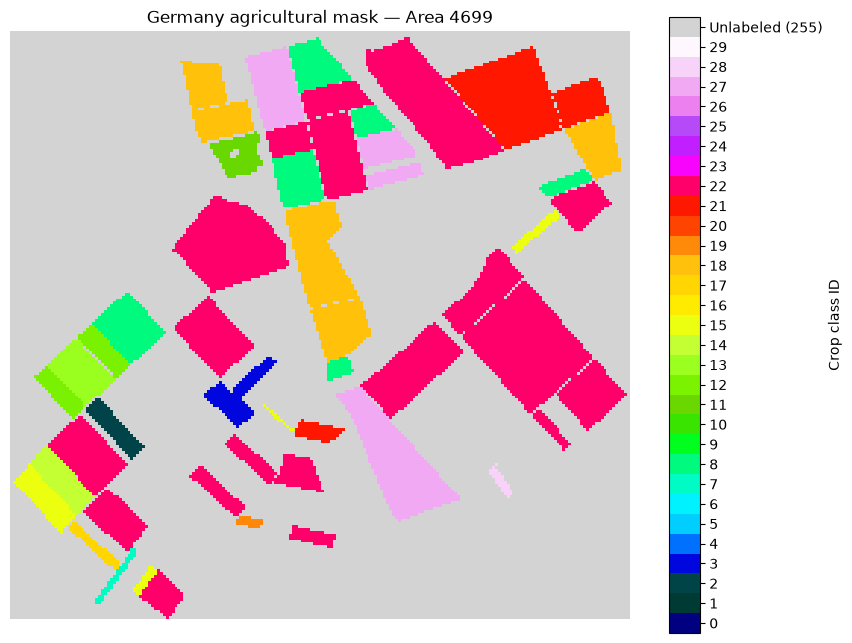

In [35]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
import numpy as np

# Select one area
area_id = next(iter(mask_paths))
mask_path = mask_paths[area_id]

with rasterio.open(mask_path) as src:
    mask = src.read(1)

# 30 colors for crop classes 1–30
crop_colors = list(plt.cm.gist_ncar(np.linspace(0, 1, 30)))

# Grey for unlabeled pixels (255)
colors = crop_colors + ["lightgrey"]
cmap = mcolors.ListedColormap(colors)

# Replace 255 with 30 for visualization only
display_mask = mask.astype(float)
display_mask[mask == 255] = 30

# Plot
fig, ax = plt.subplots(figsize=(10, 10))

im = ax.imshow(
    display_mask,
    cmap=cmap,
    vmin=-0.5,
    vmax=30.5,
    interpolation="nearest"
)

cbar = fig.colorbar(im, ax=ax, ticks=list(range(31)), shrink=0.8)
cbar.ax.set_yticklabels(
    [str(i) for i in range(30)] + ["Unlabeled (255)"]
)
cbar.set_label("Crop class ID")

ax.set_title(f"Germany agricultural mask — Area {area_id}")
ax.axis("off")
plt.show()

## 5. Tiling into Chips — 10-band experiment

We want to take our tiles into chips so that the GPU/CPU can handle the training. 

The code below sets up our labeled crop fields with crop ids 1-30 and saves the vector files as geopackages. From these we can then create our tiles. 

In [36]:
from pathlib import Path
import geopandas as gpd

vector_dir = Path("../data/processed/vectors")
vector_dir.mkdir(parents=True, exist_ok=True)

for area_id, gdf in complete_fields_by_area.items():
    # Work on a copy and assign crop IDs
    updated_gdf = gdf.copy()
    updated_gdf["crop_id"] = updated_gdf["hcat4_name"].map(crop_mapping)

    vector_path = vector_dir / f"complete_fields_area_{area_id}.gpkg"

    # Remove the old file so there is no ambiguity about its contents
    if vector_path.exists():
        vector_path.unlink()

    # Write the updated GeoPackage
    updated_gdf.to_file(
        vector_path,
        driver="GPKG",
        layer="complete_fields",
        index=False,
    )

    # Read the saved file back and verify
    check_gdf = gpd.read_file(vector_path, layer="complete_fields")

    print(
        f"Area {area_id}: "
        f"crop_id saved = {'crop_id' in check_gdf.columns}, "
        f"missing IDs = {check_gdf['crop_id'].isna().sum()}, "
        f"file = {vector_path.resolve()}"
    )

Area 4699: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_4699.gpkg
Area 5192: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_5192.gpkg
Area 3712: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_3712.gpkg
Area 10643: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_10643.gpkg
Area 3730: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_3730.gpkg
Area 20001: crop_id saved = True, missing IDs = 0, file = /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/vectors/complete_fields_area_20001.gpkg
Area 20002: crop_id saved = True, mi

#### I noticed that some pixels are found in multiple crop fields. These edge pixels can mess with the training as the spectral signature is a combination of multiple crop types. Ideally we would make an edge class that the model can learn, but for now we test to see if removing them entirely and treating them as ignore (255) is sufficient. 

In [37]:
from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import rasterize

# All 17 areas from the combined registry
area_ids = list(split_by_area.keys())

vector_dir = project_dir / "data/processed/vectors"
original_masks_dir = project_dir / "data/raw/raster"
cleaned_masks_dir = project_dir / "data/processed/masks_edge_ignored"

cleaned_masks_dir.mkdir(parents=True, exist_ok=True)

# Ignore pixels within 5 meters of field boundaries
boundary_width = 5.0

for area_id in area_ids:
    vector_path = vector_dir / f"complete_fields_area_{area_id}.gpkg"
    source_path = original_masks_dir / f"germany_mask_{area_id}.tif"
    output_path = cleaned_masks_dir / f"germany_mask_{area_id}.tif"

    if not vector_path.exists():
        raise FileNotFoundError(
            f"Missing GeoPackage for area {area_id}: {vector_path}"
        )

    if not source_path.exists():
        raise FileNotFoundError(
            f"Missing raster mask for area {area_id}: {source_path}"
        )

    fields = gpd.read_file(vector_path, layer="complete_fields")

    with rasterio.open(source_path) as src:
        original = src.read(1)
        profile = src.profile.copy()

        if src.crs is None or not src.crs.is_projected:
            raise ValueError(
                f"Expected projected CRS for area {area_id}"
            )

        # Each area may use UTM zone 31N or 32N
        fields = fields.to_crs(src.crs)

        boundary_zones = [
            geom.boundary.buffer(boundary_width)
            for geom in fields.geometry
            if geom is not None and not geom.is_empty
        ]

        if not boundary_zones:
            raise ValueError(
                f"No field boundaries found for area {area_id}"
            )

        edge_pixels = rasterize(
            ((geom, 1) for geom in boundary_zones),
            out_shape=original.shape,
            transform=src.transform,
            fill=0,
            all_touched=False,
            dtype="uint8",
        ).astype(bool)

    cleaned = original.copy()

    crop_pixels = (original >= 1) & (original <= 30)
    pixels_to_ignore = edge_pixels & crop_pixels

    cleaned[pixels_to_ignore] = 255

    profile.update(dtype="uint8", nodata=255)

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(cleaned.astype(np.uint8), 1)

    removed = int(pixels_to_ignore.sum())
    total = int(crop_pixels.sum())
    percentage = 100 * removed / max(total, 1)

    print(
        f"Area {area_id}: ignored {removed:,} of {total:,} "
        f"crop pixels ({percentage:.1f}%)"
    )

print("\nBoundary-cleaned masks saved to:", cleaned_masks_dir)

Area 4699: ignored 1,712 of 13,086 crop pixels (13.1%)
Area 5192: ignored 2,800 of 19,248 crop pixels (14.5%)
Area 3712: ignored 2,905 of 20,428 crop pixels (14.2%)
Area 10643: ignored 3,621 of 25,176 crop pixels (14.4%)
Area 3730: ignored 4,186 of 25,935 crop pixels (16.1%)
Area 20001: ignored 8,818 of 57,974 crop pixels (15.2%)
Area 20002: ignored 18,211 of 122,303 crop pixels (14.9%)
Area 20003: ignored 14,715 of 126,287 crop pixels (11.7%)
Area 20004: ignored 18,258 of 158,416 crop pixels (11.5%)
Area 20005: ignored 18,148 of 116,587 crop pixels (15.6%)
Area 20006: ignored 23,369 of 197,241 crop pixels (11.8%)
Area 20007: ignored 12,911 of 111,991 crop pixels (11.5%)
Area 20008: ignored 21,876 of 164,456 crop pixels (13.3%)
Area 20009: ignored 32,440 of 184,137 crop pixels (17.6%)
Area 20010: ignored 26,665 of 157,336 crop pixels (16.9%)
Area 20011: ignored 17,445 of 113,728 crop pixels (15.3%)
Area 20012: ignored 20,588 of 159,897 crop pixels (12.9%)

Boundary-cleaned masks saved 

#### Quick visualization

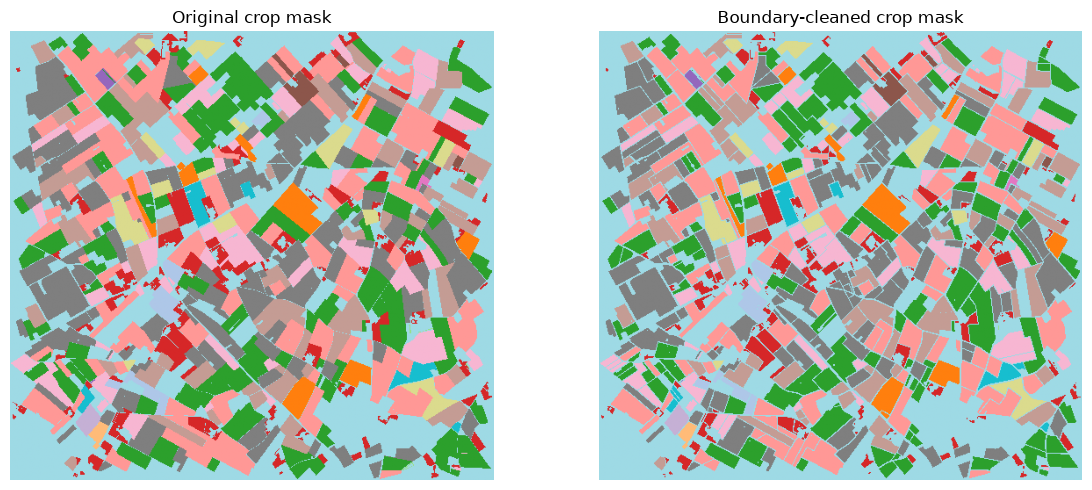

In [38]:
import matplotlib.pyplot as plt
import rasterio

area_id = 20006

original_path = original_masks_dir / f"germany_mask_{area_id}.tif"
cleaned_path = cleaned_masks_dir / f"germany_mask_{area_id}.tif"

with rasterio.open(original_path) as src:
    original = src.read(1)

with rasterio.open(cleaned_path) as src:
    cleaned = src.read(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original, vmin=1, vmax=30, cmap="tab20")
axes[0].set_title("Original crop mask")

axes[1].imshow(cleaned, vmin=1, vmax=30, cmap="tab20")
axes[1].set_title("Boundary-cleaned crop mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Correcting GeoAI crop id mapping. 
The GeoAI function for tile creation remaps crop ids in its own way and the labels that we gave it earlier would disappear. Therefore we patch the function so that it keeps the crop ids the way we labeled them. 

In [39]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds
import geoai
import inspect

training = inspect.getmodule(geoai.export_geotiff_tiles_batch)

print("GeoAI tiling module:", training.__name__)

ALLOWED_LABEL_VALUES = {0, *range(1, 31), 255}


def load_raster_labels_preserving_ids(
    class_raster_path,
    src_crs,
    quiet=False,
    metadata_format=None,
):
    """Validate raster labels without remapping crop IDs."""

    with rasterio.open(class_raster_path) as src:
        if src.crs != src_crs:
            raise ValueError(
                f"CRS mismatch: image={src_crs}, mask={src.crs}"
            )

        data = src.read(1)
        values = set(map(int, np.unique(data)))
        unexpected = values - ALLOWED_LABEL_VALUES

        if unexpected:
            raise ValueError(
                f"Unexpected label values in {class_raster_path}: "
                f"{sorted(unexpected)}"
            )

        if not quiet:
            print(
                f"Validated {class_raster_path}: "
                f"label values = {sorted(values)}"
            )

    return {i: i for i in range(1, 31)}, []


def read_label_tile_preserving_ids(
    class_raster_path,
    minx,
    miny,
    maxx,
    maxy,
    tile_size,
    class_to_id,
):
    """Read mask pixels directly, preserving class IDs."""

    with rasterio.open(class_raster_path) as src:
        bounds = src.bounds

        if (
            minx >= bounds.right
            or maxx <= bounds.left
            or miny >= bounds.top
            or maxy <= bounds.bottom
        ):
            return (
                np.full(
                    (tile_size, tile_size),
                    255,
                    dtype=np.uint8,
                ),
                False,
            )

        window = from_bounds(
            minx,
            miny,
            maxx,
            maxy,
            transform=src.transform,
        )

        data = src.read(
            1,
            window=window,
            boundless=True,
            out_shape=(tile_size, tile_size),
            fill_value=255,
        ).astype(np.uint8, copy=False)

    # Normalize any old background pixels to ignore value 255.
    data[data == 0] = 255

    values = set(map(int, np.unique(data)))
    unexpected = values - (set(range(1, 31)) | {255})

    if unexpected:
        raise ValueError(
            f"Unexpected label values in tile: "
            f"{sorted(unexpected)}"
        )

    has_crop_pixels = bool(
        np.any((data >= 1) & (data <= 30))
    )

    return data, has_crop_pixels


# Apply the patches to GeoAI's internal functions.
training._load_class_data_raster = (
    load_raster_labels_preserving_ids
)

training._rasterize_label_from_raster = (
    read_label_tile_preserving_ids
)

print("GeoAI label-preservation patches applied.")

GeoAI tiling module: geoai.utils.training
GeoAI label-preservation patches applied.


### GENERATE: Now lets make our tiles. Our scenes are about 200 pixels so making 128 x 128 with a stride of 64 makes sense.

We are pairing them by name with the vector and raster files having the same naming structure. 

In [40]:
from pathlib import Path
import shutil
import numpy as np
import rasterio
import geoai

# Use all 17 areas defined in the area-selection section
area_ids = list(split_by_area.keys())

images_dir_10 = project_dir / "data/raw/imagery/sentinel2_10band"
cleaned_masks_dir = project_dir / "data/processed/masks_edge_ignored"

batch_output_dir = project_dir / "data/processed/batch_all_10band"
batch_images_dir = batch_output_dir / "images"
batch_masks_dir = batch_output_dir / "masks"

# Check all source files BEFORE deleting any existing batch output
source_pairs = []

for area_id in area_ids:
    image_src = images_dir_10 / f"germany_2023_area_{area_id}.tif"
    mask_src = cleaned_masks_dir / f"germany_mask_{area_id}.tif"

    if not image_src.exists():
        raise FileNotFoundError(
            f"Missing Sentinel-2 image for area {area_id}: {image_src}"
        )

    if not mask_src.exists():
        raise FileNotFoundError(
            f"Missing cleaned mask for area {area_id}: {mask_src}"
        )

    with rasterio.open(image_src) as image, rasterio.open(mask_src) as mask:
        if (
            image.crs != mask.crs
            or image.transform != mask.transform
            or image.width != mask.width
            or image.height != mask.height
        ):
            raise ValueError(
                f"Image-mask grid mismatch for area {area_id}"
            )

        if image.count != 10:
            raise ValueError(
                f"Expected 10 bands for area {area_id}, got {image.count}"
            )

        values = set(map(int, np.unique(mask.read(1))))
        invalid = values - (set(range(1, 31)) | {255})

        if invalid:
            raise ValueError(
                f"Unexpected mask labels in area {area_id}: {invalid}"
            )

    source_pairs.append((area_id, image_src, mask_src))

print(f"Validated {len(source_pairs)} image-mask pairs.")

# Recreate the temporary batch directory
# WARNING: Deletes existing batch_all/ contents.
if batch_output_dir.exists():
    shutil.rmtree(batch_output_dir)

batch_images_dir.mkdir(parents=True, exist_ok=True)
batch_masks_dir.mkdir(parents=True, exist_ok=True)

# Copy all image-mask pairs with matching filenames
for area_id, image_src, mask_src in source_pairs:

    filename = f"germany_2023_area_{area_id}.tif"

    shutil.copy2(image_src, batch_images_dir / filename)
    shutil.copy2(mask_src, batch_masks_dir / filename)

    print(f"Prepared area {area_id} ({split_by_area[area_id]})")

# Ensure the GeoAI label-preservation patch was applied
import inspect

training = inspect.getmodule(geoai.export_geotiff_tiles_batch)

assert (
    training._load_class_data_raster
    is load_raster_labels_preserving_ids
), "Run the GeoAI label-preservation patch cell first."

assert (
    training._rasterize_label_from_raster
    is read_label_tile_preserving_ids
), "Run the GeoAI label-preservation patch cell first."

# Generate tiles
stats_all = geoai.export_geotiff_tiles_batch(
    images_folder=str(batch_images_dir),
    masks_folder=str(batch_masks_dir),
    output_folder=str(batch_output_dir),
    tile_size=128,
    stride=64,
    match_by_name=True,
    skip_empty_tiles=False,
    metadata_format=None,
    quiet=False,
)

print("\nBatch tiling finished.")
print(stats_all)

Validated 17 image-mask pairs.
Prepared area 4699 (train)
Prepared area 5192 (train)
Prepared area 3712 (train)
Prepared area 10643 (val)
Prepared area 3730 (test)
Prepared area 20001 (train)
Prepared area 20002 (train)
Prepared area 20003 (train)
Prepared area 20004 (train)
Prepared area 20005 (train)
Prepared area 20006 (train)
Prepared area 20007 (train)
Prepared area 20008 (train)
Prepared area 20009 (train)
Prepared area 20010 (train)
Prepared area 20011 (train)
Prepared area 20012 (train)


Processing image pairs:   0%|          | 0/17 [00:00<?, ?it/s]


Batch tiling finished.
{'total_image_pairs': 17, 'processed_pairs': 17, 'total_tiles': 717, 'tiles_with_features': 715, 'errors': 0, 'processed_files': [{'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all_10band/images/germany_2023_area_10643.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all_10band/masks/germany_2023_area_10643.tif', 'base_name': 'germany_2023_area_10643', 'tiles_generated': 9, 'tiles_with_features': 9}, {'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all_10band/images/germany_2023_area_20001.tif', 'mask': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all_10band/masks/germany_2023_area_20001.tif', 'base_name': 'germany_2023_area_20001', 'tiles_generated': 56, 'tiles_with_features': 54}, {'image': '/Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/batch_all_10band/images/germany_2023_area_20002.tif', 'mask': '/Users/henristaehe

#### ORGANIZE: Moving the tiles from different areas into training/validation/test split. 3 areas train, 1 validation, 1 test.

In [41]:
from pathlib import Path
import shutil
import re
import numpy as np
import rasterio

# Use the area registry defined earlier in the notebook
area_ids = list(split_by_area.keys())

batch_output_dir = project_dir / "data/processed/batch_all_10band"
generated_images_dir = batch_output_dir / "images"
generated_masks_dir = batch_output_dir / "masks"

final_tiles_dir = project_dir / "data/processed/tiles_10band"

allowed_values = set(range(1, 31)) | {255}

# Match generated tiles, excluding the original full-area TIFFs.
# Example: germany_2023_area_20001_3.tif
tile_pattern = re.compile(
    r"^germany_2023_area_(\d+)_(\d+)\.tif$"
)

generated_images = sorted(
    p for p in generated_images_dir.glob("*.tif")
    if tile_pattern.fullmatch(p.name)
)

generated_masks = sorted(
    p for p in generated_masks_dir.glob("*.tif")
    if tile_pattern.fullmatch(p.name)
)

# Check matching filenames
image_names = {p.name for p in generated_images}
mask_names = {p.name for p in generated_masks}

if image_names != mask_names:
    raise ValueError(
        f"Image/mask mismatch.\n"
        f"Missing masks: {image_names - mask_names}\n"
        f"Missing images: {mask_names - image_names}"
    )

if not generated_images:
    raise ValueError("No generated tiles found.")

# Validate every tile before replacing the final dataset
tile_counts_by_split = {"train": 0, "val": 0, "test": 0}
area_counts = {area_id: 0 for area_id in area_ids}

validated_tiles = []

for image_path in generated_images:

    match = tile_pattern.fullmatch(image_path.name)
    area_id = int(match.group(1))

    if area_id not in split_by_area:
        raise ValueError(
            f"Unknown area ID in tile: {image_path.name}"
        )

    split = split_by_area[area_id]
    mask_path = generated_masks_dir / image_path.name

    with rasterio.open(image_path) as image, \
         rasterio.open(mask_path) as mask:

        if (
            image.width != 128
            or image.height != 128
            or mask.width != 128
            or mask.height != 128
        ):
            raise ValueError(
                f"Unexpected tile dimensions: {image_path.name}"
            )

        if image.count != 10:
            raise ValueError(
                f"Expected 10 image bands: {image_path.name}"
            )

        if (
            image.crs != mask.crs
            or image.transform != mask.transform
        ):
            raise ValueError(
                f"Image/label alignment mismatch: {image_path.name}"
            )

        values = set(map(int, np.unique(mask.read(1))))
        invalid = values - allowed_values

        if invalid:
            raise ValueError(
                f"Unexpected label values in {mask_path.name}: "
                f"{sorted(invalid)}"
            )

    validated_tiles.append((image_path, mask_path, split))
    tile_counts_by_split[split] += 1
    area_counts[area_id] += 1

# Confirm every registered area produced tiles
missing_areas = [
    area_id for area_id, count in area_counts.items()
    if count == 0
]

if missing_areas:
    raise ValueError(
        f"No tiles generated for areas: {missing_areas}"
    )

print("All generated tiles validated.")
print("Tiles per area:", area_counts)
print("Tiles per split:", tile_counts_by_split)
print("Total:", sum(tile_counts_by_split.values()))

# Prepare replacement dataset in a separate temporary directory
staging_dir = project_dir / "data/processed/tiles_10band_staging"

if staging_dir.exists():
    shutil.rmtree(staging_dir)

for split in ["train", "val", "test"]:
    (staging_dir / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (staging_dir / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

for image_path, mask_path, split in validated_tiles:
    shutil.copy2(
        image_path,
        staging_dir / split / "images" / image_path.name
    )
    shutil.copy2(
        mask_path,
        staging_dir / split / "labels" / mask_path.name
    )

# Replace the old final dataset only after successful copying.
# Keep a backup until final validation is complete.
backup_dir = project_dir / "data/processed/tiles_10band_backup"

if backup_dir.exists():
    raise FileExistsError(
        f"Backup already exists: {backup_dir}. "
        "Move or rename it before replacing the dataset."
    )

if final_tiles_dir.exists():
    final_tiles_dir.rename(backup_dir)

staging_dir.rename(final_tiles_dir)

print("\nNew train/val/test dataset created.")
print("Output:", final_tiles_dir)
print("Previous dataset backup:", backup_dir)

All generated tiles validated.
Tiles per area: {4699: 9, 5192: 9, 3712: 9, 10643: 9, 3730: 9, 20001: 56, 20002: 56, 20003: 56, 20004: 56, 20005: 56, 20006: 56, 20007: 56, 20008: 56, 20009: 56, 20010: 56, 20011: 56, 20012: 56}
Tiles per split: {'train': 699, 'val': 9, 'test': 9}
Total: 717

New train/val/test dataset created.
Output: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/tiles_10band
Previous dataset backup: /Users/henristaehelin/Desktop/UZH/SDS320/project/data/processed/tiles_10band_backup


### VALIDATE
Now as a final check we want to ensure we made tiles, that they are separated into train, validation and test tiles. And that all the images and tiles are accounted for, ensuring that image names equal label names and same for image width.  

In [42]:

allowed_values = set(range(1, 31)) | {255}
summary = {}

for split in ["train", "val", "test"]:
    image_dir = final_tiles_dir / split / "images"
    label_dir = final_tiles_dir / split / "labels"

    images = sorted(image_dir.glob("*.tif"))
    labels = sorted(label_dir.glob("*.tif"))

    image_names = {p.name for p in images}
    label_names = {p.name for p in labels}

    if image_names != label_names:
        raise ValueError(
            f"{split}: image-label filename mismatch. "
            f"Missing labels: {image_names - label_names}; "
            f"missing images: {label_names - image_names}"
        )

    for image_path in images:
        label_path = label_dir / image_path.name

        with rasterio.open(image_path) as image, \
             rasterio.open(label_path) as label:
            if (
                image.width != label.width
                or image.height != label.height
                or image.crs != label.crs
                or image.transform != label.transform
            ):
                raise ValueError(
                    f"Grid mismatch in {split}: {image_path.name}"
                )

            values = set(map(int, np.unique(label.read(1))))
            invalid = values - allowed_values

            if invalid:
                raise ValueError(
                    f"Unexpected label IDs in {label_path.name}: "
                    f"{sorted(invalid)}"
                )

    summary[split] = len(images)

assert summary == tile_counts_by_split, (
    f"Final dataset counts {summary} do not match "
    f"the validated tile counts {tile_counts_by_split}"
) ### Defensive coding

print("Final tile counts:", summary)
print("Total tiles:", sum(summary.values()))
print("All image-label pairs and label IDs validated.")


Final tile counts: {'train': 699, 'val': 9, 'test': 9}
Total tiles: 717
All image-label pairs and label IDs validated.


In [43]:

from pathlib import Path
from collections import Counter

import numpy as np
import rasterio
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader


In [44]:

tiles_dir = project_dir / "data/processed/tiles_10band"
splits = ["train", "val", "test"]

class_names = {
    1: "alfalfa_lucerne",
    2: "asparagus",
    3: "beans",
    4: "buckwheat",
    5: "carrots_daucus",
    6: "clover",
    7: "lupins",
    8: "maize_corn_popcorn",
    9: "miscanthus_silvergrass",
    10: "peas",
    11: "permanent_grassland",
    12: "potatoes",
    13: "soy_soybeans",
    14: "spring_barley",
    15: "spring_common_soft_wheat",
    16: "spring_oats",
    17: "strawberries",
    18: "sugar_beet",
    19: "sunflower",
    20: "temporary_grassland",
    21: "winter_barley",
    22: "winter_common_soft_wheat",
    23: "winter_durum_hard_wheat",
    24: "winter_emmer",
    25: "winter_mixed_grains",
    26: "winter_oats",
    27: "winter_rapeseed_rape",
    28: "winter_rye",
    29: "winter_spelt",
    30: "winter_triticale",
}

pixel_counts = {split: Counter() for split in splits}

for split in splits:
    label_dir = tiles_dir / split / "labels"

    for label_path in sorted(label_dir.glob("*.tif")):
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        values, counts = np.unique(mask, return_counts=True)
        for value, count in zip(values, counts):
            pixel_counts[split][int(value)] += int(count)

for split in splits:
    labeled_pixels = sum(
        count for label, count in pixel_counts[split].items()
        if 1 <= label <= 30
    )
    ignored_pixels = pixel_counts[split].get(255, 0)

    print(f"\n{split.upper()}")
    print("Crop-labeled pixels:", f"{labeled_pixels:,}")
    print("Ignored pixels (255):", f"{ignored_pixels:,}")
    print("Crop classes present:", sum(
        pixel_counts[split].get(i, 0) > 0 for i in range(1, 31)
    ))



TRAIN
Crop-labeled pixels: 5,243,577
Ignored pixels (255): 6,208,839
Crop classes present: 30

VAL
Crop-labeled pixels: 90,500
Ignored pixels (255): 56,956
Crop classes present: 17

TEST
Crop-labeled pixels: 88,171
Ignored pixels (255): 59,285
Crop classes present: 16


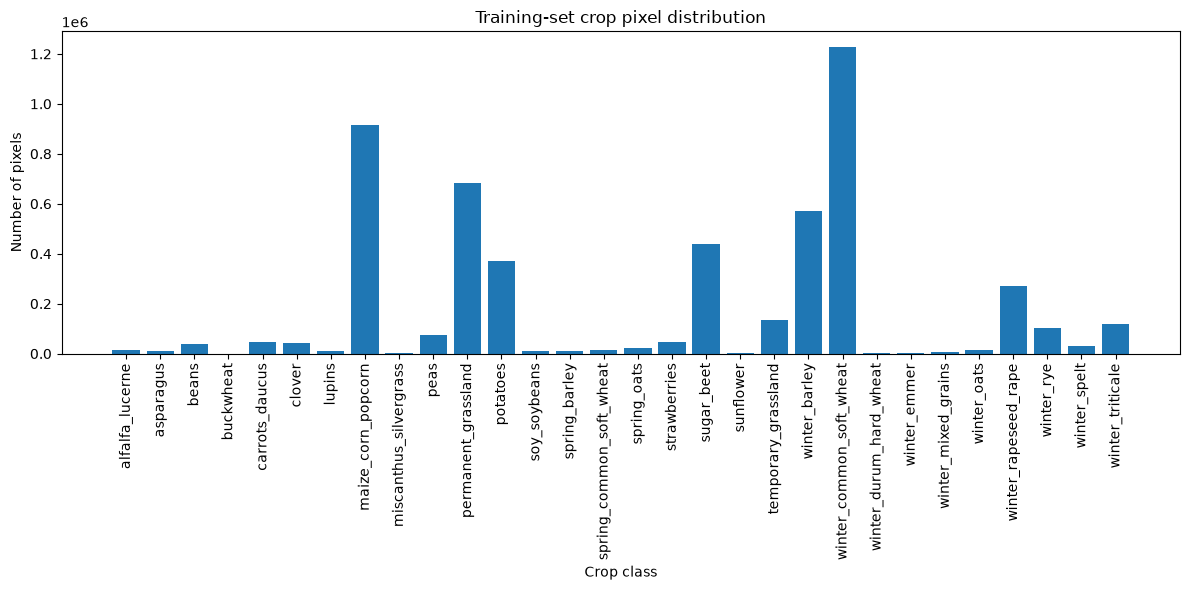

In [45]:

train_counts = [
    pixel_counts["train"].get(class_id, 0)
    for class_id in range(1, 31)
]

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(
    [class_names[i] for i in range(1, 31)],
    train_counts
)
ax.set_title("Training-set crop pixel distribution")
ax.set_xlabel("Crop class")
ax.set_ylabel("Number of pixels")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()


## 6. Model training — 10-band experiment

### Prepare training and validation datasets

In [46]:
from pathlib import Path
import shutil
import numpy as np
import rasterio

tiles_dir = project_dir / "data/processed/tiles_10band"
geoai_input_dir = project_dir / "data/processed/geoai_training_input_10band"

# Only recreate the dedicated GeoAI staging folder.
if geoai_input_dir.exists():
    shutil.rmtree(geoai_input_dir)

stage_images = geoai_input_dir / "images"
stage_labels = geoai_input_dir / "labels"

stage_images.mkdir(parents=True)
stage_labels.mkdir(parents=True)

split_names = {"train": set(), "val": set()}

for split in ["train", "val"]:
    image_dir = tiles_dir / split / "images"
    label_dir = tiles_dir / split / "labels"

    images = sorted(image_dir.glob("*.tif"))
    labels = sorted(label_dir.glob("*.tif"))

    assert {p.name for p in images} == {p.name for p in labels}

    for image_path in images:
        name = image_path.name

        # Distinct area IDs guarantee non-overlapping split membership.
        expected_ids = [
            area_id
            for area_id, assigned_split in split_by_area.items()
            if assigned_split == split
]
        assert any(
            name.startswith(f"germany_2023_area_{area_id}_")
            for area_id in expected_ids
        ), f"Unexpected {split} tile: {name}"

        with rasterio.open(image_path) as src:
            image = src.read().astype(np.float32)
            image_profile = src.profile.copy()

        with rasterio.open(label_dir / name) as src:
            labels_array = src.read(1)
            label_profile = src.profile.copy()

        assert image.shape[0] == 10
        assert np.all(
            ((labels_array >= 1) & (labels_array <= 30))
            | (labels_array == 255)
        )

        # GeoAI divides images by 255 when loading.
        # Convert Sentinel-2 scaled reflectance into that range.
        # Assumes original values use the 10,000 reflectance scale.
        image = np.clip(image / 10000.0, 0, 1) * 255.0

        image_profile.update(dtype="float32")
        with rasterio.open(stage_images / name, "w", **image_profile) as dst:
            dst.write(image)

        # Model classes 0–29, with 255 still ignored.
        valid = labels_array != 255
        labels_array = labels_array.copy()
        labels_array[valid] -= 1

        label_profile.update(dtype="uint8", nodata=255)
        with rasterio.open(stage_labels / name, "w", **label_profile) as dst:
            dst.write(labels_array.astype(np.uint8), 1)

        split_names[split].add(name)

# Verify staging contains every tile from the final dataset
for split in ["train", "val"]:
    source_images = list(
        (tiles_dir / split / "images").glob("*.tif")
    )

    assert len(split_names[split]) == len(source_images), (
        f"{split}: expected {len(source_images)} tiles, "
        f"but staged {len(split_names[split])}"
    )

assert split_names["train"].isdisjoint(split_names["val"]) #ensures geographic separation between training and validation
assert split_names["train"]
assert split_names["val"]

print("Training areas:", [
    area_id for area_id, split in split_by_area.items()
    if split == "train"
])
print("Validation areas:", [
    area_id for area_id, split in split_by_area.items()
    if split == "val"
])

print("Training tiles:", len(split_names["train"]))
print("Validation tiles:", len(split_names["val"]))
print("Test tiles used: 0")
print("GeoAI inputs prepared.")

Training areas: [4699, 5192, 3712, 20001, 20002, 20003, 20004, 20005, 20006, 20007, 20008, 20009, 20010, 20011, 20012]
Validation areas: [10643]
Training tiles: 699
Validation tiles: 9
Test tiles used: 0
GeoAI inputs prepared.


#### Adding weights to our crop classes in an inverse square root proportion. These treats rarer classes with more weight. 

In [47]:
import numpy as np
import rasterio

train_labels_dir = project_dir / "data/processed/tiles_10band/train/labels"

# Original crop IDs are 1–30.
crop_pixel_counts = np.zeros(30, dtype=np.int64)

for label_path in sorted(train_labels_dir.glob("*.tif")):
    with rasterio.open(label_path) as src:
        mask = src.read(1)

    valid = (mask >= 1) & (mask <= 30)

    crop_pixel_counts += np.bincount(
        mask[valid].astype(int) - 1,
        minlength=30
    )

# Use inverse square-root frequencies.
# This weights rare classes more without being too extreme.
present = crop_pixel_counts > 0

weights = np.ones(30, dtype=np.float64)

weights[present] = 1 / np.sqrt(crop_pixel_counts[present])

# Normalize so the average weight of present classes is 1.
weights[present] /= weights[present].mean()

# Prevent extremely rare classes receiving excessive weights.
weights[present] = np.clip(weights[present], 0.2, 5.0)

# Classes absent from training get neutral weights.
weights[~present] = 1.0

class_weights = weights.tolist()

print("Classes present in training:", present.sum(), "/ 30")

for crop_id in range(1, 31):
    print(
        f"Crop {crop_id:2d}: "
        f"{crop_pixel_counts[crop_id - 1]:>8,} pixels, "
        f"weight = {weights[crop_id - 1]:.3f}"
    )

Classes present in training: 30 / 30
Crop  1:   16,233 pixels, weight = 0.884
Crop  2:   10,254 pixels, weight = 1.112
Crop  3:   38,654 pixels, weight = 0.573
Crop  4:      364 pixels, weight = 5.000
Crop  5:   46,100 pixels, weight = 0.524
Crop  6:   43,621 pixels, weight = 0.539
Crop  7:    8,893 pixels, weight = 1.194
Crop  8:  916,459 pixels, weight = 0.200
Crop  9:    2,659 pixels, weight = 2.184
Crop 10:   76,485 pixels, weight = 0.407
Crop 11:  683,560 pixels, weight = 0.200
Crop 12:  369,237 pixels, weight = 0.200
Crop 13:   12,433 pixels, weight = 1.010
Crop 14:   12,126 pixels, weight = 1.023
Crop 15:   13,503 pixels, weight = 0.969
Crop 16:   21,568 pixels, weight = 0.767
Crop 17:   45,023 pixels, weight = 0.531
Crop 18:  439,757 pixels, weight = 0.200
Crop 19:    2,774 pixels, weight = 2.138
Crop 20:  133,297 pixels, weight = 0.308
Crop 21:  570,754 pixels, weight = 0.200
Crop 22: 1,228,856 pixels, weight = 0.200
Crop 23:    2,322 pixels, weight = 2.337
Crop 24:    1,352 p

In [48]:
print("Minimum weight:", min(class_weights))
print("Maximum weight:", max(class_weights))
print("Mean weight:", np.mean(class_weights))

Minimum weight: 0.2
Maximum weight: 5.0
Mean weight: 0.9812629297424521


#### Now finally train our model!

In [49]:
import geoai
import inspect
import torch

train_fn = inspect.unwrap(geoai.train_segmentation_model)
scope = train_fn.__globals__

assert "train_test_split" in scope, (
    "GeoAI's split implementation has changed. "
    "Check the installed version before training."
)

original_split = scope["train_test_split"]


def geographic_split(image_files, label_files, **kwargs):
    """Use the existing geographic split instead of a random split."""

    assert len(image_files) == len(label_files)

    pairs = list(zip(image_files, label_files))

    for image_path, label_path in pairs:
        assert Path(image_path).name == Path(label_path).name

    train_pairs = [
        pair for pair in pairs
        if Path(pair[0]).name in split_names["train"]
    ]
    val_pairs = [
        pair for pair in pairs
        if Path(pair[0]).name in split_names["val"]
    ]

    assert len(train_pairs) == len(split_names["train"])
    assert len(val_pairs) == len(split_names["val"])
    assert len(train_pairs) + len(val_pairs) == len(pairs)

    print(
    f"Fixed geographic split: "
    f"{len(train_pairs)} train, "
    f"{len(val_pairs)} validation"
)

    return (
        [p[0] for p in train_pairs],
        [p[0] for p in val_pairs],
        [p[1] for p in train_pairs],
        [p[1] for p in val_pairs],
    )


model_dir = project_dir / "models/unet_geoai_imagenet_cropweighted_10band"
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

try:
    scope["train_test_split"] = geographic_split

    result = geoai.train_segmentation_model(
        images_dir=str(stage_images),
        labels_dir=str(stage_labels),
        output_dir=str(model_dir),
        architecture="unet",
        encoder_name="resnet18",
        encoder_weights="imagenet",
        class_weights=class_weights,
        num_channels=10,
        num_classes=30,
        batch_size=3,
        num_epochs=10,
        learning_rate=0.001,
        val_split=0.25,  # Replaced by our geographic split patch
        ignore_index=255,
        num_workers=0,
        device=device,
        verbose=True,
        plot_curves=True,
    )

finally:
    scope["train_test_split"] = original_split

print("Training finished.")
print("Model directory:", model_dir)

Fixed geographic split: 699 train, 9 validation
Training finished.
Model directory: /Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted_10band


#### The model works! Its probably not very good though.

## 7. Model evaluation

#### Plot training performance

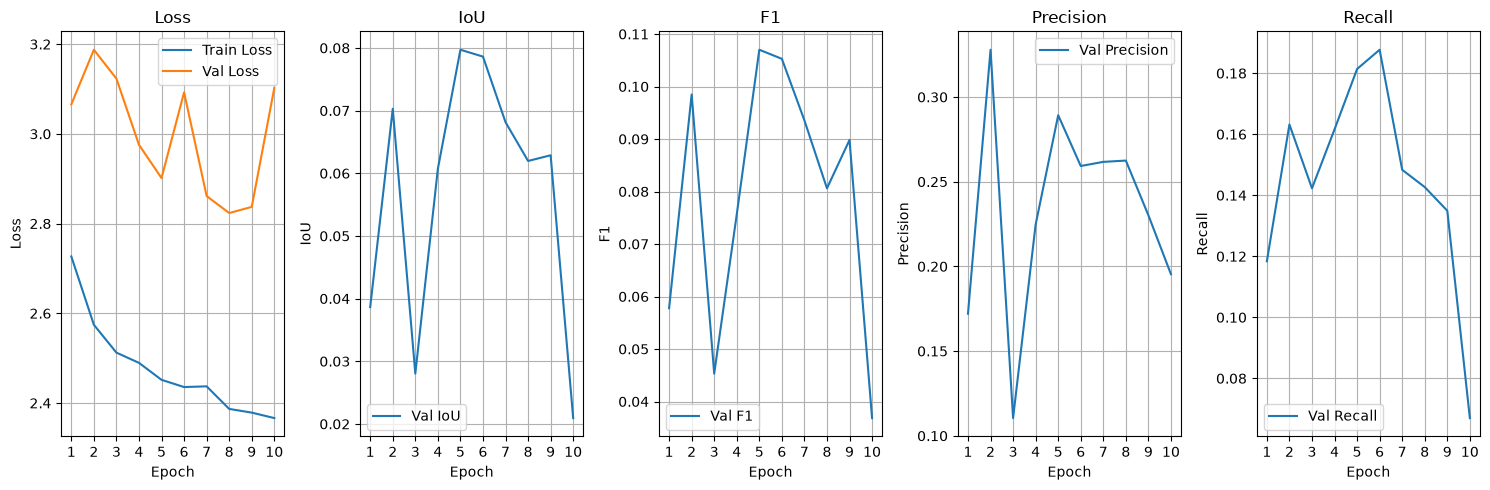

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,2.726757,3.065797,0.038645,0.057780,0.172056,0.118383
1,2,2.574454,3.187539,0.070294,0.098482,0.327913,0.163196
2,3,2.512381,3.123132,0.028031,0.045306,0.110449,0.142279
3,4,2.489581,2.975629,0.060715,0.075642,0.224752,0.161597
4,5,2.451748,2.901543,0.079714,0.107006,0.289267,0.181384
5,6,2.435636,3.092608,0.078619,0.105279,0.259271,0.187684
6,7,2.437232,2.861428,0.068158,0.093552,0.261719,0.148343
7,8,2.386902,2.823558,0.061966,0.080608,0.262476,0.142678
8,9,2.378660,2.837265,0.062874,0.089825,0.230174,0.134923
9,10,2.366480,3.102334,0.020937,0.036845,0.195396,0.066985


In [50]:
import geoai

model_dir = project_dir / "models/unet_geoai_imagenet_cropweighted_10band"

geoai.plot_performance_metrics(
    history_path=str(model_dir / "training_history.pth"),
    figsize=(15, 5),
    verbose=True,
)

The model is overfitting, as train loss decreases as validation loss increases. Also IoU is lower in epoch 10 than epoch 1.

#### Create predictions of crop type of validation tiles

In [51]:
from pathlib import Path
import rasterio
import numpy as np
import torch

model_dir = project_dir / "models/unet_geoai_imagenet_cropweighted_10band"
model_path = model_dir / "best_model.pth"

val_images_dir = (
    project_dir / "data/processed/geoai_training_input_10band/images"
)

val_labels_dir = (
    project_dir / "data/processed/tiles_10band/val/labels"
)

predictions_dir = model_dir / "validation_predictions"
predictions_dir.mkdir(parents=True, exist_ok=True)

val_images = sorted(
    p for p in val_images_dir.glob("germany_2023_area_10643_*.tif")
    if p.stem.rsplit("_", 1)[-1].isdigit()
)

assert model_path.exists(), f"Model not found: {model_path}"
assert len(val_images) == 9, (
    f"Expected 9 validation tiles, found {len(val_images)}"
)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

for image_path in val_images:
    output_path = predictions_dir / image_path.name

    geoai.semantic_segmentation(
        input_path=str(image_path),
        output_path=str(output_path),
        model_path=str(model_path),
        architecture="unet",
        encoder_name="resnet18",
        num_channels=10,
        num_classes=30,
        window_size=128,
        overlap=0,
        batch_size=1,
        device=device,
        quiet=True,
    )

print(f"Predictions created: {len(val_images)}")
print("Saved to:", predictions_dir)

Predictions created: 9
Saved to: /Users/henristaehelin/Desktop/UZH/SDS320/project/models/unet_geoai_imagenet_cropweighted_10band/validation_predictions


#### Calculate pixel accuracy and IoU

In [52]:
confusion = np.zeros((30, 30), dtype=np.int64)

for image_path in val_images:
    label_path = val_labels_dir / image_path.name
    prediction_path = predictions_dir / image_path.name

    with rasterio.open(label_path) as src:
        truth = src.read(1)

    with rasterio.open(prediction_path) as src:
        prediction = src.read(1).astype(np.int64)

    assert prediction.shape == truth.shape
    assert np.all((prediction >= 0) & (prediction < 30))

    # Evaluate crop pixels only; ignore background and boundaries.
    valid = (truth >= 1) & (truth <= 30)

    actual = truth[valid].astype(np.int64) - 1
    predicted = prediction[valid]

    confusion += np.bincount(
        30 * actual + predicted,
        minlength=30 * 30
    ).reshape(30, 30)

intersection = np.diag(confusion)
actual_count = confusion.sum(axis=1)
predicted_count = confusion.sum(axis=0)
union = actual_count + predicted_count - intersection

present = actual_count > 0
iou = np.divide(
    intersection, union,
    out=np.zeros(30, dtype=float),
    where=union > 0
)

pixel_accuracy = intersection.sum() / max(confusion.sum(), 1)
mean_iou = iou[present].mean()

print(f"Validation pixel accuracy: {pixel_accuracy:.2%}")
print(f"Validation mean IoU:       {mean_iou:.2%}")
print(f"Crop classes in validation: {present.sum()} / 30")

print("\nPer-class IoU (original crop IDs):")
for crop_id in range(1, 31):
    if present[crop_id - 1]:
        print(f"Crop {crop_id:2d}: {iou[crop_id - 1]:.2%}")

Validation pixel accuracy: 27.39%
Validation mean IoU:       8.76%
Crop classes in validation: 17 / 30

Per-class IoU (original crop IDs):
Crop  1: 0.00%
Crop  3: 0.00%
Crop  6: 0.00%
Crop  8: 92.39%
Crop 10: 0.00%
Crop 11: 26.39%
Crop 12: 0.00%
Crop 13: 0.00%
Crop 14: 0.00%
Crop 17: 0.00%
Crop 20: 0.00%
Crop 21: 7.18%
Crop 22: 22.91%
Crop 27: 0.00%
Crop 28: 0.00%
Crop 29: 0.00%
Crop 30: 0.00%


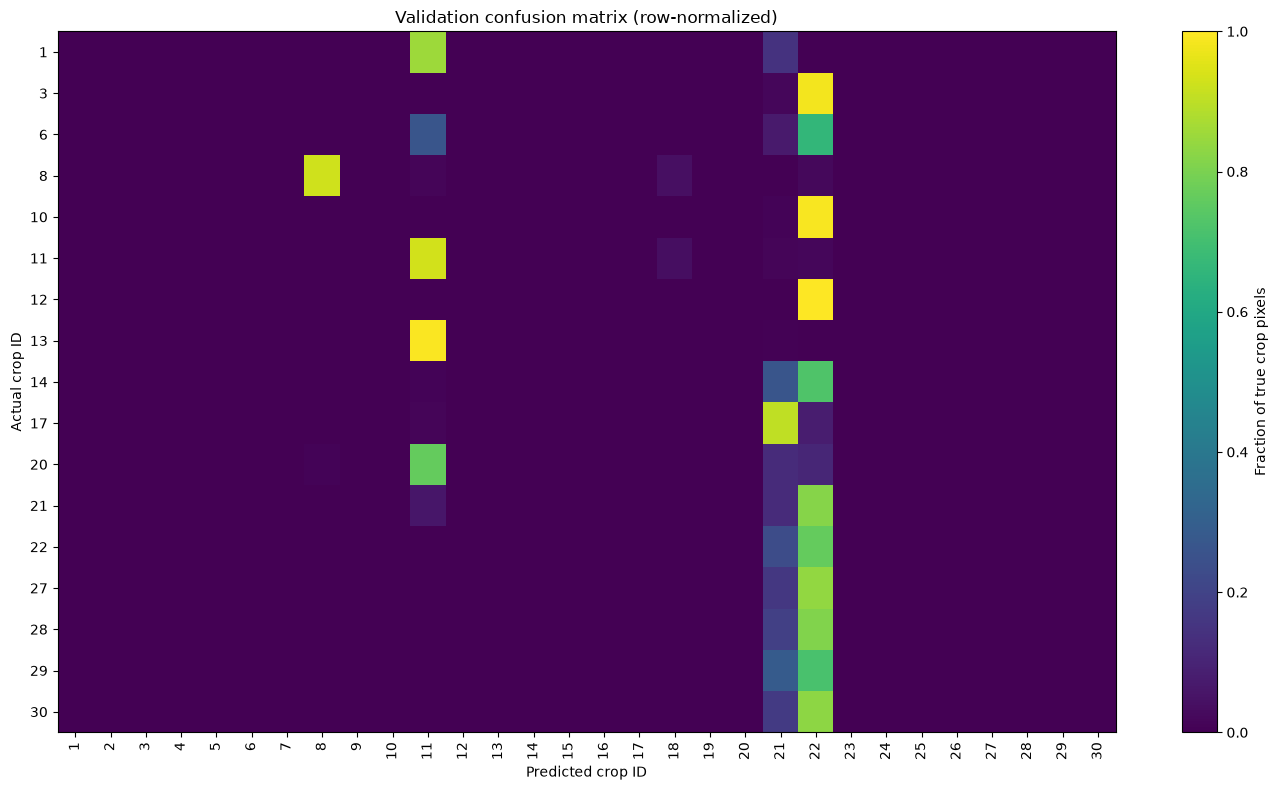

In [53]:
import matplotlib.pyplot as plt
import numpy as np

# Keep only crop classes present in validation
present_ids = np.where(confusion.sum(axis=1) > 0)[0]

# Show where each true class's pixels were predicted.
# Include all 30 prediction columns to retain errors.
cm = confusion[present_ids, :].astype(float)
cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(14, 8))

im = ax.imshow(cm, cmap="viridis", vmin=0, vmax=1, aspect="auto")

ax.set_yticks(np.arange(len(present_ids)))
ax.set_yticklabels([str(i + 1) for i in present_ids])

ax.set_xticks(np.arange(30))
ax.set_xticklabels(range(1, 31), rotation=90)

ax.set_xlabel("Predicted crop ID")
ax.set_ylabel("Actual crop ID")
ax.set_title("Validation confusion matrix (row-normalized)")

plt.colorbar(im, ax=ax, label="Fraction of true crop pixels")
plt.tight_layout()
plt.show()

Pixel accuracy is low, 27.72%. Also IoU is extremely low even for the crops. 

#### Visualize a prediction

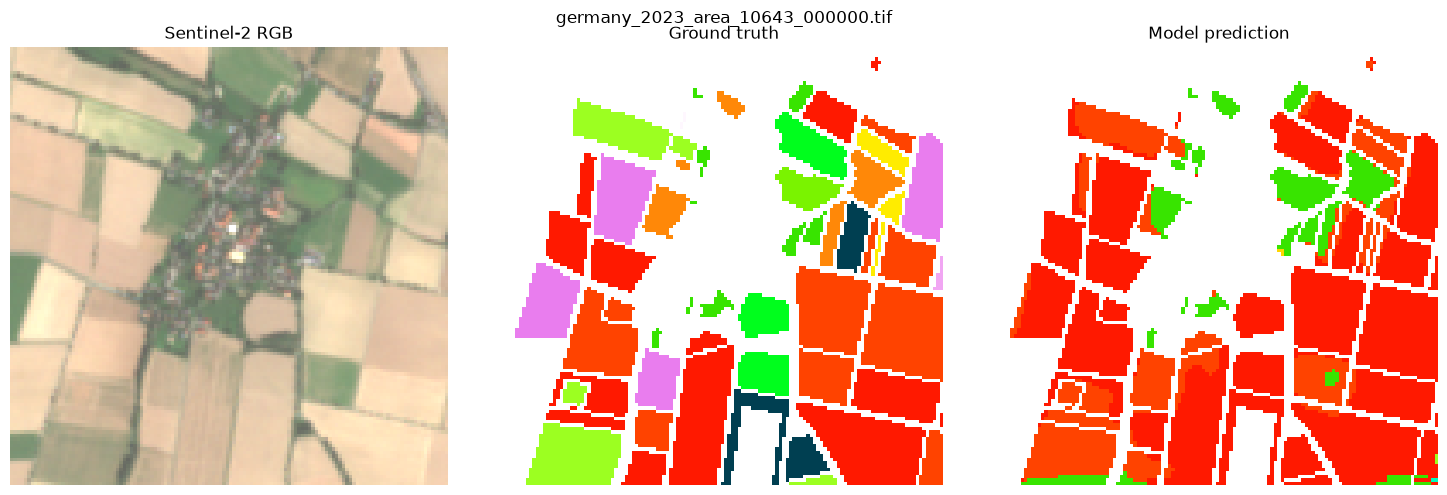

In [54]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

image_path = val_images[0]

original_image_path = (
    project_dir / "data/processed/tiles_10band/val/images"
    / image_path.name
)

with rasterio.open(original_image_path) as src:
    image = src.read().astype(np.float32)

with rasterio.open(val_labels_dir / image_path.name) as src:
    truth = src.read(1)

with rasterio.open(predictions_dir / image_path.name) as src:
    prediction = src.read(1).astype(np.int64) + 1

# Assumes band order B2, B3, B4, B8.
rgb = np.moveaxis(image[[2, 1, 0]], 0, -1)
rgb = np.clip(rgb / 3000.0, 0, 1)

colors = plt.get_cmap("gist_ncar", 30)(
    np.arange(30)
)
cmap = ListedColormap(colors)
cmap.set_bad("white")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB")

axes[1].imshow(
    np.ma.masked_equal(truth, 255),
    cmap=cmap, vmin=0.5, vmax=30.5
)
axes[1].set_title("Ground truth")

axes[2].imshow(
    np.ma.masked_where(truth == 255, prediction),
    cmap=cmap, vmin=0.5, vmax=30.5
)
axes[2].set_title("Model prediction")

for ax in axes:
    ax.axis("off")

plt.suptitle(image_path.name)
plt.tight_layout()
plt.show()

The image shows the prediction of crop types from a semantic segmentation model of a small 2 by 2 km field in Germany. It compares the ground truth (middle) to the model prediction (right). The model struggles to identify between different crop types, likely because many of them are rare and there are a few crop types which heavily dominate the training dataset. However it is able to delineate between crop fields which is pretty neat. 

#### It is likely that the strong class imbalance makes training difficult. Ideally we see what classes the model predicts too frequently.

In [55]:
import numpy as np
import rasterio
from collections import Counter

true_counts = Counter()
pred_counts = Counter()

for image_path in val_images:
    with rasterio.open(val_labels_dir / image_path.name) as src:
        truth = src.read(1)

    with rasterio.open(predictions_dir / image_path.name) as src:
        prediction = src.read(1).astype(np.int64) + 1

    # Only compare pixels with a valid ground-truth crop label
    valid = (truth >= 1) & (truth <= 30)

    true_counts.update(truth[valid].tolist())
    pred_counts.update(prediction[valid].tolist())

print("Most common true crop classes:")
print(true_counts.most_common(10))

print("\nMost common predicted crop classes:")
print(pred_counts.most_common(10))

Most common true crop classes:
[(22, 21198), (21, 17040), (27, 13095), (10, 6913), (14, 6313), (28, 5779), (8, 5387), (3, 3537), (30, 2079), (29, 2040)]

Most common predicted crop classes:
[(22, 65742), (21, 13791), (11, 5676), (8, 5004), (18, 284), (14, 3)]
